# EGN 2203 – Introduction to Data Science · Course Project

## Predicting Machine Failure in a Milling Process
### AI4I 2020 Predictive Maintenance Dataset

| | |
|---|---|
| **Group** | X *(replace with your group number, and rename the file `EGN2203_Project_GroupX.ipynb` to match)* |
| **Members** | Firomsa Mohammed Aman – H00540196<br>Kidus Tesfaye Beyecha – H00540185<br>Henok Habtamu Mamo – H00540189 |
| **Course** | EGN 2203 – Introduction to Data Science |
| **Dataset** | AI4I 2020 Predictive Maintenance Dataset, UCI Machine Learning Repository (CC BY 4.0) |

---

### Executive summary

* **Data.** 10,000 simulated machining processes (14 columns) with no missing values. 27 records whose failure labels contradict each other were removed, leaving 9,973 processes, of which 330 (3.3 %) failed.
* **Statistics.** Failed processes run at a 10.8 N·m (27 %) higher mean torque (Welch t-test, $p < 0.001$, large effect). Failure depends on the product variant (χ² test, $p < 0.001$; L 3.9 % vs H 2.0 %), although all variants are machined under the same conditions (ANOVA, $p = 0.87$).
* **Features.** Mechanical power ($P = \tau\omega$), tool wear × torque and the process–air temperature difference reproduce the documented failure physics exactly, and raise the decision tree's cross-validated $F_1$ from 0.61 to 0.89.
* **Model.** A tuned Random Forest catches 58 of 66 failures in the held-out test set with only 3 false alarms ($F_1$ = 0.91, ROC-AUC = 0.99). The tuned decision tree is almost as good and rediscovers the documented failure limits as readable rules.
* **Engineering takeaway.** Monitor power and wear × torque in real time, watch the cooling margin, and replace tools on a wear schedule (≈ 200 min): tool-wear failures have random timing, and no snapshot model can predict them.

### Contents

1. [Problem Definition & Engineering Context](#1.-Problem-Definition-&-Engineering-Context)
2. [Data Understanding & Cleaning](#2.-Data-Understanding-&-Cleaning)
3. [Exploratory Data Analysis & Visualization](#3.-Exploratory-Data-Analysis-&-Visualization)
4. [Statistical Inference & Hypothesis Testing](#4.-Statistical-Inference-&-Hypothesis-Testing)
5. [Feature Engineering](#5.-Feature-Engineering)
6. [Machine Learning Modeling](#6.-Machine-Learning-Modeling)
7. [Engineering Interpretation & Limitations](#7.-Engineering-Interpretation-&-Limitations)
8. [References](#8.-References)

**How to run this notebook.** Place `ai4i2020.csv` in a `data/` folder next to this notebook (or directly next to it), then choose *Run All*. Every random step uses the fixed seed `RANDOM_STATE = 42`, so every number below is reproduced exactly on each run. A full run takes roughly one to two minutes on a laptop.

## 0. Setup

All libraries below are the ones used in the EGN 2203 labs and companion notebooks: **pandas** and **NumPy** for data handling, **Matplotlib** and **seaborn** for plots, **SciPy** and **statsmodels** for hypothesis tests, and **scikit-learn** for machine learning.

**Colour convention used in every chart:** <span style="color:#2a78d6">**blue = no failure**</span> (normal operation), <span style="color:#eb6834">**orange = failure**</span>, <span style="color:#1baf7a">**aqua**</span> = a second series that is *not* a failure (for example, process temperature next to air temperature), and **dark grey dashed lines = engineering limits or reference values**. Blue and orange were chosen because they remain distinguishable for readers with red–green colour blindness.

In [1]:
# ------------------------------------------------------------------
# 0. Setup: libraries, reproducibility settings and plotting style
# ------------------------------------------------------------------
import sys
import warnings
from pathlib import Path

import numpy as np                    # numerical computing
import pandas as pd                   # tables (DataFrames)
import matplotlib
import matplotlib.pyplot as plt       # plotting
import seaborn as sns                 # statistical plots built on Matplotlib
import scipy
from scipy import stats               # t-test, chi-square, Levene and Shapiro-Wilk tests
import statsmodels
import statsmodels.api as sm                              # ANOVA table (sm.stats.anova_lm)
from statsmodels.formula.api import ols                   # linear model that ANOVA is built on
from statsmodels.stats.multicomp import MultiComparison   # Tukey post-hoc comparisons
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)

# Reproducibility: one seed, used everywhere randomness appears (splits, sampling, models)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# seaborn's boxplot passes an argument that Matplotlib 3.11 deprecated. The warning comes from
# inside seaborn, not from our code, and does not change the plot, so we hide only that message.
warnings.filterwarnings("ignore", message="vert: bool was deprecated")

# Colours (see the colour convention above)
COLOR_OK = "#2a78d6"     # blue   = no failure / main series
COLOR_FAIL = "#eb6834"   # orange = failure (reserved for failures in every chart)
COLOR_ALT = "#1baf7a"    # aqua   = a second series that is not a failure
COLOR_REF = "#52514e"    # dark grey = limits and reference lines
STATUS_ORDER = ["No failure", "Failure"]
STATUS_PALETTE = {"No failure": COLOR_OK, "Failure": COLOR_FAIL}

# Plot style: light solid grid, no top/right frame, readable font size
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.6
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.axisbelow"] = True      # draw the grid behind bars and points, not on top

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Record the exact versions so the results can be reproduced later
print("Python       :", sys.version.split()[0])
print("pandas       :", pd.__version__)
print("NumPy        :", np.__version__)
print("Matplotlib   :", matplotlib.__version__)
print("seaborn      :", sns.__version__)
print("SciPy        :", scipy.__version__)
print("statsmodels  :", statsmodels.__version__)
print("scikit-learn :", sklearn.__version__)

Python       : 3.14.4
pandas       : 3.1.1
NumPy        : 2.5.4
Matplotlib   : 3.11.2
seaborn      : 0.13.2
SciPy        : 1.18.1
statsmodels  : 0.15.0
scikit-learn : 1.9.1


## 1. Problem Definition & Engineering Context

### 1.1 The engineering system

The dataset describes a **milling machine**: a machine tool in which a rotating cutting tool removes material from a workpiece. Each of the 10,000 rows is one **machining process** (one job on one product). For every process the machine records the ambient air temperature, the process temperature, the spindle's rotational speed and torque, and how many minutes the current cutting tool has already been used (**tool wear**). Products come in three quality variants: **L**ow (about 50 % of products), **M**edium (30 %) and **H**igh (20 %).

A process ends in **machine failure** if at least one of five failure mechanisms occurs:

| Code | Failure mechanism | Physical idea |
|---|---|---|
| TWF | Tool wear failure | the tool is worn out and breaks, or is replaced, near the end of its life |
| HDF | Heat dissipation failure | the process cannot get rid of its heat: the process–air temperature gap is small **and** the spindle turns slowly |
| PWF | Power failure | the mechanical power drawn is outside the drive's working window (too low or too high) |
| OSF | Overstrain failure | a worn tool is loaded with high torque: the tool is over-strained |
| RNF | Random failure | a failure with no relation to the process conditions |

> **Important: the data are synthetic.** AI4I 2020 was published by S. Matzka (2020) because real predictive-maintenance data are rarely made public. The dataset "reflects real predictive maintenance data encountered in industry", but the values were **generated by a simulation with documented rules**, not recorded on a real machine. We use the documented rules to *check* our analysis (Sections 2 and 5), and Section 7 discusses what the synthetic origin means for real-world use.

### 1.2 What is measured

| Variable (original name) | Unit | Meaning | Role in this project |
|---|---|---|---|
| `UDI` | – | row number 1–10,000, in production order | identifier (not a model input) |
| `Product ID` | – | quality letter + serial number | identifier (not a model input) |
| `Type` | – | product quality variant L / M / H | input |
| `Air temperature [K]` | K | ambient temperature around the machine | input |
| `Process temperature [K]` | K | temperature of the machining process | input |
| `Rotational speed [rpm]` | rpm | spindle speed, revolutions per minute | input |
| `Torque [Nm]` | N·m | twisting load on the spindle and tool | input |
| `Tool wear [min]` | min | minutes the current tool has been in use | input |
| `Machine failure` | 0 / 1 | 1 if the process failed | **target (what we predict)** |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | 0 / 1 | which mechanism(s) caused the failure | used for diagnosis only, **never as model inputs** |

Temperatures are in kelvin (K). A temperature *difference* of 1 K is the same as 1 °C, and 300 K ≈ 27 °C.

### 1.3 Why these data matter in engineering practice

* **Unplanned stoppages are expensive.** A failed process scraps the workpiece, can damage the tool and spindle, stops production and, in the worst case (a breaking tool), is a safety hazard.
* **Maintenance strategy.** *Reactive* maintenance repairs after failure; *preventive* maintenance replaces parts on a fixed schedule (safe, but throws away useful tool life); **predictive maintenance** acts when the data show that failure is near. Predictive maintenance is only possible if we can link sensor readings to failures, which is what this project does.
* **The two kinds of error have different costs.** A *missed failure* (false negative) means unplanned downtime and possible damage; a *false alarm* (false positive) means an unnecessary stop or inspection. Our model evaluation (Section 6) is built around this trade-off rather than around plain accuracy.

### 1.4 Analytical questions

| # | Question | How we answer it |
|---|---|---|
| **Q1** | Do processes that fail run under significantly different operating conditions than processes that do not, in particular under a different **torque** (mechanical load)? | EDA (Section 3) and a two-sample t-test (Section 4.1) |
| **Q2** | Does the **product quality variant** (L/M/H) change the probability of failure, and if so, is that because the variants are machined under different conditions? | Chi-square test of independence (4.2) and one-way ANOVA (4.3) |
| **Q3** | Can failure be **predicted** from the sensor readings, which physically motivated features help most, and which failure mechanisms remain hard to predict? | Feature engineering (Section 5) and classification models (Section 6) |

## 2. Data Understanding & Cleaning

### 2.1 Load and inspect the raw data

In [2]:
# Locate the data file: first in a data/ folder (project layout), then next to the notebook
candidate_paths = [Path("data") / "ai4i2020.csv", Path("ai4i2020.csv")]
DATA_PATH = None
for path in candidate_paths:
    if path.exists():
        DATA_PATH = path
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "ai4i2020.csv was not found. Download it from https://archive.ics.uci.edu/dataset/601 "
        "and put it in a folder called 'data' next to this notebook."
    )

raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape (rows, columns):", raw.shape)
raw.head()

Loaded: data\ai4i2020.csv
Shape (rows, columns): (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# Column names, data types and non-null counts
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
# Summary statistics of every numeric column (transposed so each variable is one row)
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


**First look.** The file has 10,000 rows (processes) and 14 columns. `Product ID` and `Type` are text; all other columns are numeric. The value ranges are physically sensible for a machine shop: air temperature 295.3–304.5 K (about 22–31 °C), process temperature 305.7–313.8 K, spindle speed 1,168–2,886 rpm, torque 3.8–76.6 N·m and tool wear 0–253 min. The mean of `Machine failure` is 0.034, so **only 3.4 % of processes fail**: the classes are strongly imbalanced, which shapes every later decision.

### 2.2 Rename the columns

Names such as `Air temperature [K]` contain spaces and brackets, which make code clumsy and error-prone. We rename every column to a short `snake_case` name **that keeps the unit in the name** (for example `air_temp_k`), so the unit is never lost.

In [5]:
# Short, code-friendly column names that keep the unit in the name
column_names = {
    "UDI": "udi",
    "Product ID": "product_id",
    "Type": "type",
    "Air temperature [K]": "air_temp_k",
    "Process temperature [K]": "process_temp_k",
    "Rotational speed [rpm]": "rot_speed_rpm",
    "Torque [Nm]": "torque_nm",
    "Tool wear [min]": "tool_wear_min",
    "Machine failure": "machine_failure",
    "TWF": "twf", "HDF": "hdf", "PWF": "pwf", "OSF": "osf", "RNF": "rnf",
}
df = raw.rename(columns=column_names)

# Groups of columns we refer to repeatedly
SENSOR_COLS = ["air_temp_k", "process_temp_k", "rot_speed_rpm", "torque_nm", "tool_wear_min"]
MODE_COLS = ["twf", "hdf", "pwf", "osf", "rnf"]

# Axis labels with units, used by every plot so units are never forgotten
LABELS = {
    "air_temp_k": "Air temperature [K]",
    "process_temp_k": "Process temperature [K]",
    "rot_speed_rpm": "Rotational speed [rpm]",
    "torque_nm": "Torque [N·m]",
    "tool_wear_min": "Tool wear [min]",
    "temp_diff_k": "Process − air temperature [K]",
    "power_w": "Mechanical power [W]",
    "strain_minnm": "Tool wear × torque [min·N·m]",
}
MODE_NAMES = {"twf": "Tool wear (TWF)", "hdf": "Heat dissipation (HDF)", "pwf": "Power (PWF)",
              "osf": "Overstrain (OSF)", "rnf": "Random (RNF)"}

print(df.columns.tolist())

['udi', 'product_id', 'type', 'air_temp_k', 'process_temp_k', 'rot_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure', 'twf', 'hdf', 'pwf', 'osf', 'rnf']


### 2.3 Missing values

In [6]:
# Count and percentage of missing values in every column
missing_table = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2),
    "data_type": df.dtypes.astype(str),
})
print("Total missing values in the dataset:", int(df.isnull().sum().sum()))
missing_table

Total missing values in the dataset: 0


,missing_count,missing_percent,data_type
udi,0,0.0,int64
product_id,0,0.0,str
type,0,0.0,str
air_temp_k,0,0.0,float64
process_temp_k,0,0.0,float64
rot_speed_rpm,0,0.0,int64
torque_nm,0,0.0,float64
tool_wear_min,0,0.0,int64
machine_failure,0,0.0,int64
twf,0,0.0,int64


**Result:** there are **no missing values** in any column, so no imputation (filling-in) is needed. This is a consequence of the data being simulated. On a real machine, sensors drop out and records go missing; an imputation choice would then need an engineering justification (for example, never filling a missing torque reading with the average torque, because extreme torque is exactly what signals a failure).

### 2.4 Duplicates, gaps in the sequence and inconsistent identifiers

In [7]:
# Duplicated records
print("Fully duplicated rows        :", df.duplicated().sum())
print("Duplicated UDI values        :", df["udi"].duplicated().sum())
print("Duplicated Product IDs       :", df["product_id"].duplicated().sum())

# Time gaps: UDI is the production order, so consecutive values should differ by exactly 1
udi_steps = df["udi"].diff().dropna()
print("UDI range                    :", df["udi"].min(), "to", df["udi"].max())
print("Gaps in the UDI sequence     :", (udi_steps != 1).sum())

# Consistency: the first letter of Product ID should equal the Type column
print("Product ID letter != Type    :", (df["product_id"].str[0] != df["type"]).sum())
print()
print("Processes per product type:")
print(df["type"].value_counts())

Fully duplicated rows        : 0
Duplicated UDI values        : 0
Duplicated Product IDs       : 0
UDI range                    : 1 to 10000
Gaps in the UDI sequence     : 0
Product ID letter != Type    : 0

Processes per product type:
type
L    6000
M    2997
H    1003
Name: count, dtype: int64


**Result:** no duplicated rows or IDs, **no gaps** in the production sequence (UDI runs from 1 to 10,000 in steps of exactly 1), and the quality letter in `Product ID` always agrees with `Type`. The type mix (L 6,000 · M 2,997 · H 1,003) matches the documented 50/30/20 % split.

### 2.5 Physically impossible or corrupted values

Instead of only looking for "unusual" numbers, we check each variable against **physical limits** that any real reading must satisfy.

In [8]:
# Each check counts rows that would be physically implausible for a running milling machine
plausibility = pd.DataFrame({
    "check": [
        "Air temperature outside 290–310 K (17–37 °C workshop range)",
        "Process temperature not above air temperature",
        "Rotational speed <= 0 rpm",
        "Torque <= 0 N·m",
        "Tool wear < 0 min",
    ],
    "rows_failing_check": [
        ((df["air_temp_k"] < 290) | (df["air_temp_k"] > 310)).sum(),
        (df["process_temp_k"] <= df["air_temp_k"]).sum(),
        (df["rot_speed_rpm"] <= 0).sum(),
        (df["torque_nm"] <= 0).sum(),
        (df["tool_wear_min"] < 0).sum(),
    ],
})
plausibility

,check,rows_failing_check
0,Air temperature outside 290–310 K (17–37 °C wo...,0
1,Process temperature not above air temperature,0
2,Rotational speed <= 0 rpm,0
3,Torque <= 0 N·m,0
4,Tool wear < 0 min,0


**Result:** every reading passes every physical check, so there are no corrupted sensor values to remove or repair.

### 2.6 Label integrity: do the failure labels agree with each other?

`Machine failure` should be 1 **if and only if** at least one of the five mechanism flags is 1. This is a data-integrity check that is easy to skip and important not to: if the *target* labels are wrong, every model trained on them learns the error.

In [9]:
# Number of failure mechanisms flagged on each row
df["n_modes"] = df[MODE_COLS].sum(axis=1)

# Cross-tabulate the target against the number of flagged mechanisms
label_check = pd.crosstab(df["machine_failure"], df["n_modes"], margins=True)
label_check.columns.name = "mechanisms flagged →"
label_check

mechanisms flagged →,0,1,2,3,All
machine_failure,,,,,
0,9643,18,0,0,9661
1,9,306,23,1,339
All,9652,324,23,1,10000


In [10]:
# The two kinds of contradiction
failure_without_cause = (df["machine_failure"] == 1) & (df["n_modes"] == 0)
cause_without_failure = (df["machine_failure"] == 0) & (df["n_modes"] > 0)
print("Machine failure = 1 but no mechanism flagged :", failure_without_cause.sum())
print("Mechanism flagged but machine failure = 0    :", cause_without_failure.sum())
print("  ... mechanisms flagged on those rows       :", df.loc[cause_without_failure, MODE_COLS].sum().to_dict())

# Compare the flag counts in the file with the counts stated in the dataset documentation (UCI page)
documentation_check = pd.DataFrame({
    "flags_in_file": df[MODE_COLS].sum(),
    "count_in_documentation": [51, 115, 95, 98, 5],
})
documentation_check.index = [MODE_NAMES[m] for m in MODE_COLS]
documentation_check

Machine failure = 1 but no mechanism flagged : 9
Mechanism flagged but machine failure = 0    : 18
  ... mechanisms flagged on those rows       : {'twf': 0, 'hdf': 0, 'pwf': 0, 'osf': 0, 'rnf': 18}


,flags_in_file,count_in_documentation
Tool wear (TWF),46,51
Heat dissipation (HDF),115,115
Power (PWF),95,95
Overstrain (OSF),98,98
Random (RNF),19,5


**Findings.**

1. **9 processes** are labelled as failures although no failure mechanism is flagged.
2. **18 processes** carry a *random failure* (RNF) flag although the machine did **not** fail.
3. The file does not fully match its own documentation. The HDF, PWF and OSF counts match exactly, but the documentation reports 51 tool-wear failures and 5 random failures, while the file flags 46 and 19.

**Decision: remove the 27 contradictory records (0.27 % of the data).** A record that says "failed, cause unknown", or "random failure, but no failure", contradicts itself, so we cannot tell which of its labels is wrong. Keeping them would put label noise into the target; relabelling them would mean inventing data. Removing them changes the failure count only from 339 to 330. (In section 5.2 we also check that none of the 27 rows meets any documented HDF, PWF or OSF failure condition, which supports treating them as unreliable labels rather than as real failures.) In a real plant these records would be sent back to the maintenance team for correction instead of being deleted.

In [11]:
# Remove the contradictory records and keep the production order
rows_before = len(df)
failures_before = df["machine_failure"].sum()
removed_rows = df.loc[failure_without_cause | cause_without_failure].copy()   # kept aside for a later check

df_clean = df.loc[~(failure_without_cause | cause_without_failure)].copy()
df_clean = df_clean.drop(columns="n_modes").reset_index(drop=True)

print(f"Rows     : {rows_before:,} -> {len(df_clean):,}  (removed {rows_before - len(df_clean)})")
print(f"Failures : {failures_before} -> {df_clean['machine_failure'].sum()}")
print(f"Failure rate after cleaning: {df_clean['machine_failure'].mean():.2%}")

Rows     : 10,000 -> 9,973  (removed 27)
Failures : 339 -> 330
Failure rate after cleaning: 3.31%


### 2.7 Outliers

We use the **interquartile range (IQR) rule** from the course: a value is an outlier if it lies more than $1.5 \times \mathrm{IQR}$ below the first quartile $Q_1$ or above the third quartile $Q_3$, where $\mathrm{IQR} = Q_3 - Q_1$. For each variable we also ask an engineering question: **how often do the outlier processes fail?**

In [12]:
# IQR outlier fences for each sensor, and the failure rate of the processes outside them
overall_rate = df_clean["machine_failure"].mean()
outlier_rows = []
for col in SENSOR_COLS:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_outlier = (df_clean[col] < lower) | (df_clean[col] > upper)
    n_out = int(is_outlier.sum())
    outlier_rows.append({
        "variable": LABELS[col],
        "lower_fence": round(lower, 1),
        "upper_fence": round(upper, 1),
        "n_outliers": n_out,
        "failure_rate_of_outliers_%": round(df_clean.loc[is_outlier, "machine_failure"].mean() * 100, 1) if n_out > 0 else np.nan,
    })

outlier_table = pd.DataFrame(outlier_rows)
print(f"Failure rate of ALL processes: {overall_rate:.2%}")
outlier_table

Failure rate of ALL processes: 3.31%


,variable,lower_fence,upper_fence,n_outliers,failure_rate_of_outliers_%
0,Air temperature [K],293.5,306.3,0,NaN
1,Process temperature [K],305.4,314.6,0,NaN
2,Rotational speed [rpm],1139.5,1895.5,418,8.4
3,Torque [N·m],13.0,67.0,70,88.6
4,Tool wear [min],-110.5,325.5,0,NaN


**Decision: keep all outliers.** Temperatures and tool wear have no outliers. Rotational speed and torque do, but these "outliers" are not measurement errors:

* They are **physically achievable** operating points for a milling spindle (up to 2,886 rpm, up to 76.6 N·m), and they passed the plausibility checks in 2.5.
* They are **where the failures are.** Processes with outlying torque fail about **27 times more often** than average, and processes with outlying speed about 2.5 times more often (exact rates in the table above).

Deleting them would delete most of the signal we want to detect. Outlier handling must ask *why* a value is extreme before removing it. The tree-based models in Section 6 split on thresholds, so extreme values do not distort them; for logistic regression we standardise the features.

### 2.8 Noise, filtering and aggregation

Each row is **one process with one reading per variable**. It is not a continuous high-frequency signal (as a vibration recording would be), so there is no waveform to filter and no natural time window to aggregate over. Smoothing across rows would average *different jobs* together and blur exactly the extreme values that indicate failure. We therefore **do not filter or aggregate the data**: the random variation in the readings is part of the data, and the model has to cope with it. A rolling average is used only for *visualisation* of slow trends in Section 3.

### 2.9 Summary of missing values and preprocessing actions

In [13]:
# Required output: one table that documents every cleaning check, its result and the action taken
pd.set_option("display.max_colwidth", None)
preprocessing_summary = pd.DataFrame([
    {"check": "Missing values",
     "result": f"{int(df.isnull().sum().sum())} missing values in {df.shape[1] - 1} original columns",
     "action": "None needed",
     "justification": "Complete simulated records; no imputation required"},
    {"check": "Duplicates / gaps",
     "result": f"{df.duplicated().sum()} duplicate rows; {(udi_steps != 1).sum()} gaps in UDI 1–10,000",
     "action": "None needed",
     "justification": "Each process appears exactly once, in production order"},
    {"check": "Identifier consistency",
     "result": "Product ID letter always matches Type",
     "action": "None needed",
     "justification": "Type can be trusted as the quality variant"},
    {"check": "Physical plausibility",
     "result": f"{int(plausibility['rows_failing_check'].sum())} implausible readings",
     "action": "None needed",
     "justification": "All values inside physical limits (temperature, speed, torque, wear)"},
    {"check": "Label contradictions",
     "result": f"{failure_without_cause.sum()} failures without cause, {cause_without_failure.sum()} RNF flags without failure",
     "action": f"Removed {rows_before - len(df_clean)} rows",
     "justification": "Self-contradictory labels cannot be trusted; 0.27 % of data"},
    {"check": "Documentation vs file",
     "result": "TWF 46 vs 51 documented; RNF 19 vs 5 documented",
     "action": "Recorded as a limitation",
     "justification": "Mechanism flags are not used as model inputs"},
    {"check": "Outliers (IQR rule)",
     "result": f"{int(outlier_table['n_outliers'].sum())} outlying values (speed and torque only)",
     "action": "Kept",
     "justification": "Physically possible and strongly linked to failure (the signal to detect)"},
    {"check": "Noise / filtering",
     "result": "One reading per process; no continuous signal",
     "action": "No filtering or aggregation",
     "justification": "Smoothing would mix different jobs and hide the extremes"},
    {"check": "Column names",
     "result": "Spaces and brackets in names",
     "action": "Renamed to snake_case with units",
     "justification": "Easier, safer code; units kept in the name"},
])
preprocessing_summary

,check,result,action,justification
0,Missing values,0 missing values in 14 original columns,None needed,Complete simulated records; no imputation required
1,Duplicates / gaps,"0 duplicate rows; 0 gaps in UDI 1–10,000",None needed,"Each process appears exactly once, in production order"
2,Identifier consistency,Product ID letter always matches Type,None needed,Type can be trusted as the quality variant
3,Physical plausibility,0 implausible readings,None needed,"All values inside physical limits (temperature, speed, torque, wear)"
4,Label contradictions,"9 failures without cause, 18 RNF flags without failure",Removed 27 rows,Self-contradictory labels cannot be trusted; 0.27 % of data
5,Documentation vs file,TWF 46 vs 51 documented; RNF 19 vs 5 documented,Recorded as a limitation,Mechanism flags are not used as model inputs
6,Outliers (IQR rule),488 outlying values (speed and torque only),Kept,Physically possible and strongly linked to failure (the signal to detect)
7,Noise / filtering,One reading per process; no continuous signal,No filtering or aggregation,Smoothing would mix different jobs and hide the extremes
8,Column names,Spaces and brackets in names,Renamed to snake_case with units,"Easier, safer code; units kept in the name"


In [14]:
# Required output: save the cleaned dataset next to the raw file
CLEAN_PATH = DATA_PATH.parent / "ai4i2020_clean.csv"
df_clean.to_csv(CLEAN_PATH, index=False)
print("Cleaned dataset saved to:", CLEAN_PATH)
print("Shape:", df_clean.shape)

Cleaned dataset saved to: data\ai4i2020_clean.csv
Shape: (9973, 14)


## 3. Exploratory Data Analysis & Visualization

We add a text column `status` ("No failure" / "Failure") so that every plot has readable legend labels.

In [15]:
# Readable outcome label for plots (the numeric target machine_failure stays unchanged)
df_clean["status"] = df_clean["machine_failure"].map({0: "No failure", 1: "Failure"})
df_clean["status"].value_counts()

status
No failure    9643
Failure        330
Name: count, dtype: int64

### 3.1 How rare is failure, and which mechanisms cause it?

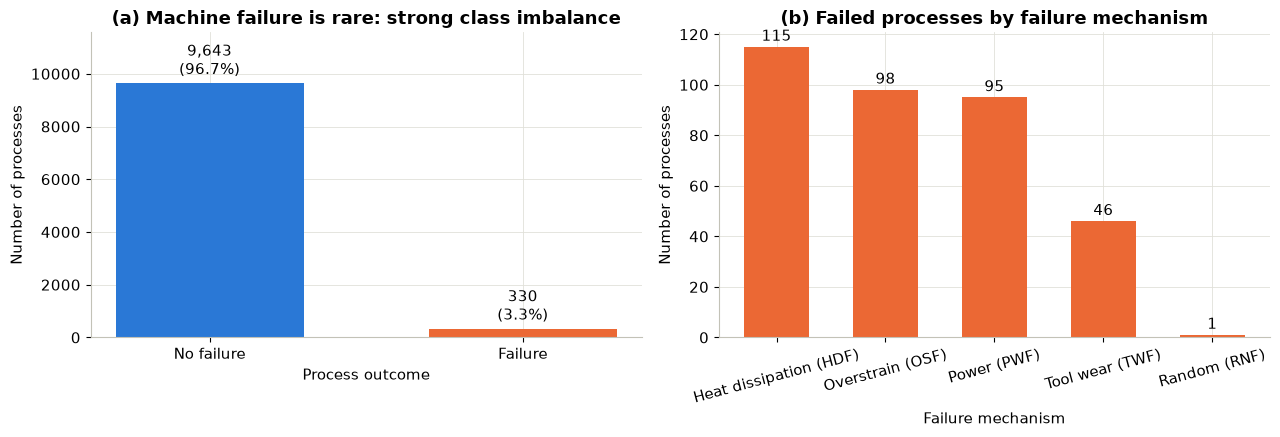

Processes with more than one mechanism: 24


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Outcome counts: the class imbalance
counts = df_clean["status"].value_counts().reindex(STATUS_ORDER)
axes[0].bar(counts.index, counts.values, color=[COLOR_OK, COLOR_FAIL], width=0.6)
for i, value in enumerate(counts.values):
    axes[0].text(i, value + 150, f"{value:,}\n({value / counts.sum():.1%})", ha="center", va="bottom")
axes[0].set_ylim(0, counts.max() * 1.2)
axes[0].set_title("(a) Machine failure is rare: strong class imbalance")
axes[0].set_xlabel("Process outcome")
axes[0].set_ylabel("Number of processes")

# (b) How often each failure mechanism occurs (a process can have several)
mode_counts = df_clean[MODE_COLS].sum().sort_values(ascending=False)
axes[1].bar([MODE_NAMES[m] for m in mode_counts.index], mode_counts.values, color=COLOR_FAIL, width=0.6)
for i, value in enumerate(mode_counts.values):
    axes[1].text(i, value + 1, str(value), ha="center", va="bottom")
axes[1].set_title("(b) Failed processes by failure mechanism")
axes[1].set_xlabel("Failure mechanism")
axes[1].set_ylabel("Number of processes")
axes[1].tick_params(axis="x", labelrotation=15)

plt.tight_layout()
plt.show()

print("Processes with more than one mechanism:", int((df_clean[MODE_COLS].sum(axis=1) > 1).sum()))

**Interpretation.**

* Only **3.3 % of processes fail** (about 1 in 30). A "model" that always answers *no failure* would already be 96.7 % accurate while being useless, so **accuracy is the wrong yardstick** for this problem. Section 6 therefore uses precision, recall and F1, and keeps the failure proportion equal in the training and test sets (a *stratified* split).
* Heat dissipation (HDF) is the most common mechanism, followed by overstrain (OSF), power (PWF) and tool wear (TWF). Only one random failure remains after cleaning. The bars add up to more than 330 because 24 processes failed through two or more mechanisms at once.

### 3.2 Distribution of each sensor variable

The histograms use **density** (each class's bars add up to 1) instead of raw counts. With 9,643 normal and only 330 failed processes, the failure histogram would otherwise be too flat to see.

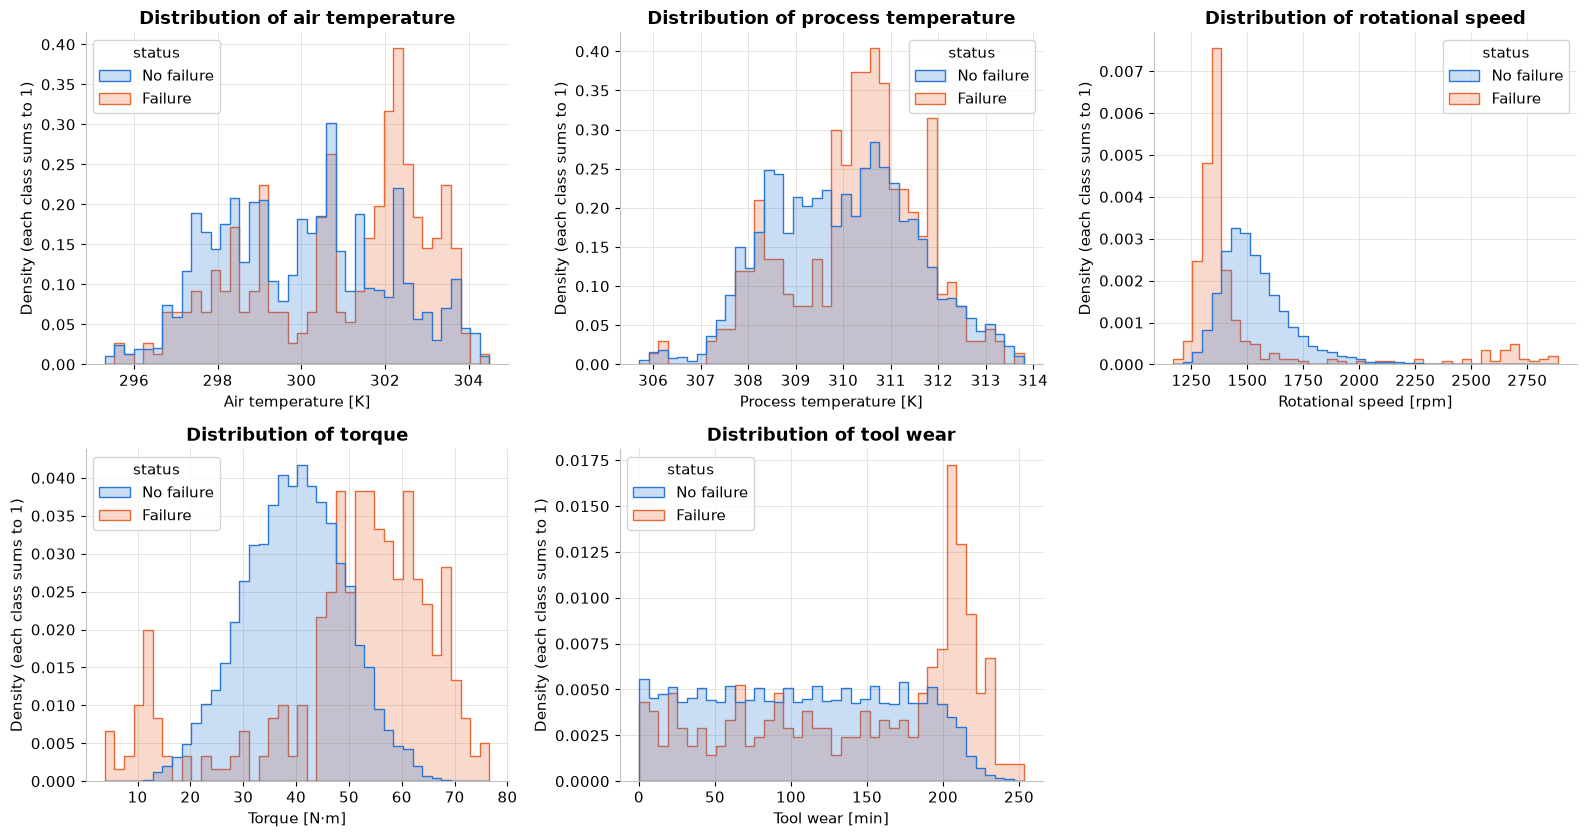

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.flat, SENSOR_COLS):
    sns.histplot(data=df_clean, x=col, hue="status", hue_order=STATUS_ORDER, palette=STATUS_PALETTE,
                 stat="density", common_norm=False, bins=40, element="step", ax=ax)
    ax.set_title(f"Distribution of {LABELS[col].split(' [')[0].lower()}")
    ax.set_xlabel(LABELS[col])
    ax.set_ylabel("Density (each class sums to 1)")
axes.flat[-1].set_axis_off()   # only five variables, so the sixth panel stays empty
plt.tight_layout()
plt.show()

**Interpretation (shape, centre, spread).**

* **Torque** is roughly bell-shaped around 40 N·m for normal processes. For failed processes it is **bimodal**: a large group at *high* torque (above about 50 N·m) and a smaller group at *very low* torque (below 20 N·m). Two different failure mechanisms are visible here; we return to this in 3.6.
* **Rotational speed** is right-skewed (a long tail towards high speeds). Failed processes are over-represented at **both** ends: very slow and very fast.
* **Tool wear** is spread almost evenly from 0 to about 250 min, because tools are used, replaced and used again (see 3.5). Failures pile up at **high wear (above about 200 min)**.
* **Air and process temperature** have a flat, irregular shape typical of a slowly drifting quantity. Failures lean towards the warmer end.

### 3.3 Normal vs failed processes: boxplots

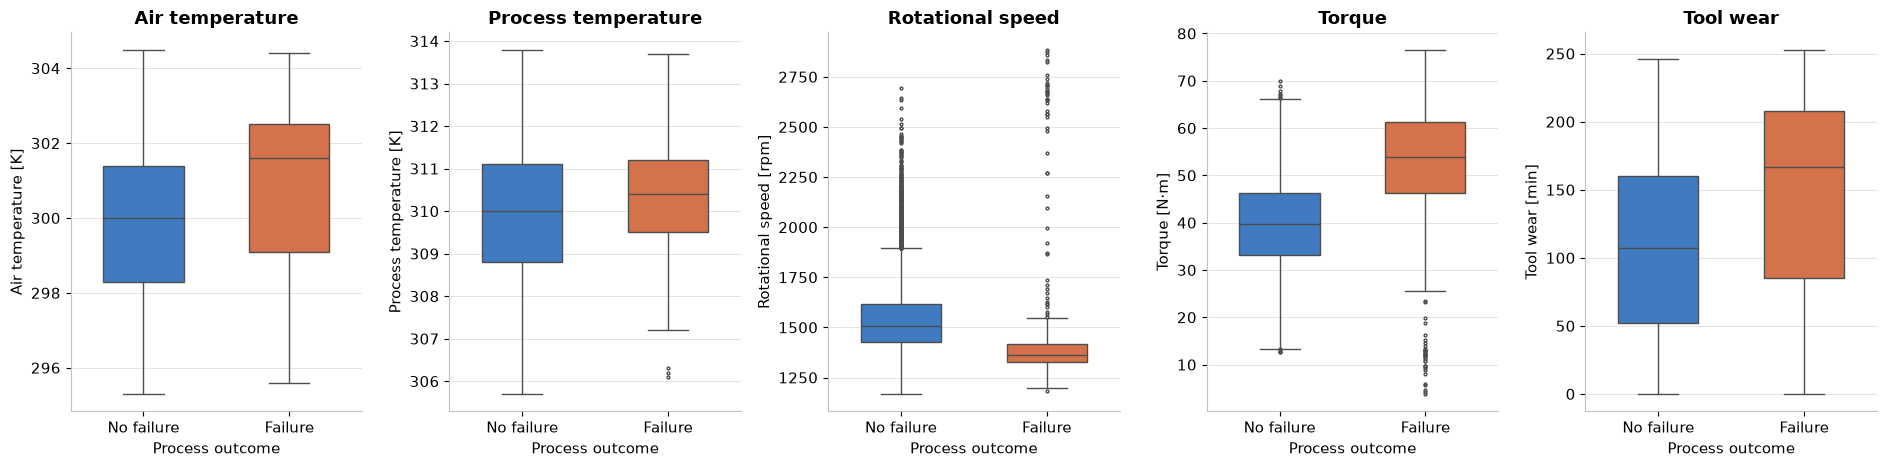

status                 No failure  Failure
air_temp_k     median      300.00   301.60
               mean        299.97   300.90
               std           1.99     2.07
process_temp_k median      310.00   310.40
               mean        309.99   310.29
               std           1.49     1.37
rot_speed_rpm  median     1507.00  1363.50
               mean       1540.35  1496.18
               std         167.47   389.59
torque_nm      median       39.80    53.85
               mean         39.62    50.40
               std           9.47    16.46
tool_wear_min  median      107.00   167.00
               mean        106.67   144.51
               std          62.94    72.94

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(19, 4.8))
for ax, col in zip(axes, SENSOR_COLS):
    sns.boxplot(data=df_clean, x="status", y=col, hue="status", order=STATUS_ORDER, hue_order=STATUS_ORDER,
                palette=STATUS_PALETTE, legend=False, fliersize=2, width=0.55, ax=ax)
    ax.set_title(LABELS[col].split(" [")[0])
    ax.set_xlabel("Process outcome")
    ax.set_ylabel(LABELS[col])
plt.tight_layout()
plt.show()

# The same comparison as numbers (median and interquartile range per group)
summary_by_status = df_clean.groupby("status")[SENSOR_COLS].agg(["median", "mean", "std"]).T
summary_by_status = summary_by_status[STATUS_ORDER].round(2)
summary_by_status

**Interpretation.**

* **Torque:** failed processes have a clearly higher median (about 54 vs 40 N·m) and a much wider spread (standard deviation about 16 vs 9 N·m), because both high- and low-torque failures exist. The low-torque failures show up as the dots below the failure box.
* **Tool wear:** the median is much higher for failed processes (167 vs 107 min).
* **Rotational speed:** failed processes have a *lower* median (about 1,364 vs 1,507 rpm), because heat-dissipation failures happen at low speed. At the same time they include a cluster of very fast processes (the dots above 2,000 rpm): the low-power failures.
* **Temperatures:** failed processes ran at a warmer ambient temperature (median 301.6 vs 300.0 K); the process temperature differs less (310.4 vs 310.0 K).

The dots beyond the whiskers are the IQR outliers from Section 2.7. For torque, most of them belong to the failure group.

### 3.4 Correlation between the variables

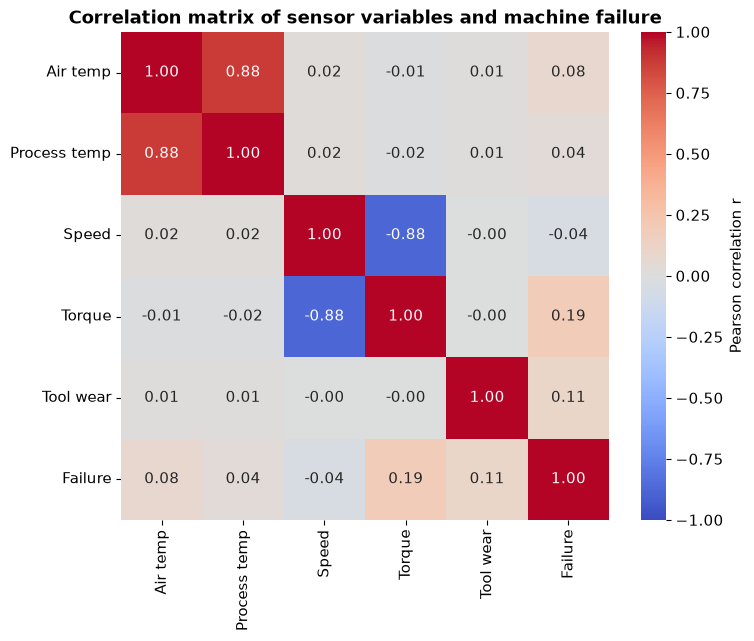

In [19]:
corr_cols = SENSOR_COLS + ["machine_failure"]
short_names = ["Air temp", "Process temp", "Speed", "Torque", "Tool wear", "Failure"]
corr = df_clean[corr_cols].corr()     # Pearson correlation coefficient r

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
            xticklabels=short_names, yticklabels=short_names, cbar_kws={"label": "Pearson correlation r"})
plt.grid(False)   # no gridlines across the coloured cells
plt.title("Correlation matrix of sensor variables and machine failure")
plt.tight_layout()
plt.show()

**Interpretation.**

* **Speed and torque: $r \approx -0.88$.** This is physics, not coincidence. Mechanical power is $P = \tau\,\omega$ (torque × angular speed). The machine runs near a typical power level, so when the speed goes up the torque goes down.
* **Air and process temperature: $r \approx +0.88$.** The process heats up *on top of* the ambient temperature, so the two move together.
* **Tool wear is uncorrelated with everything else.** How old the tool is does not depend on the operating point, as expected.
* **Every correlation with failure is weak ($|r| \le 0.2$).** Pearson's $r$ only measures *straight-line* relationships. The failure mechanisms are **thresholds** ("too hot *and* too slow", power "too low *or* too high"), which a single correlation number cannot capture. This tells us to engineer features that match the physics (Section 5) and to use models that can learn thresholds (decision trees, Section 6).

### 3.5 Trends and cycles along the production sequence

The rows are stored in production order, so `udi` acts as a **time axis** (we do not know the clock time between processes, only their order). Panel (b) uses the temperature *difference* that drives heat dissipation, and panel (d) a **rolling average** over 500 consecutive processes to show how the failure rate changes over time.

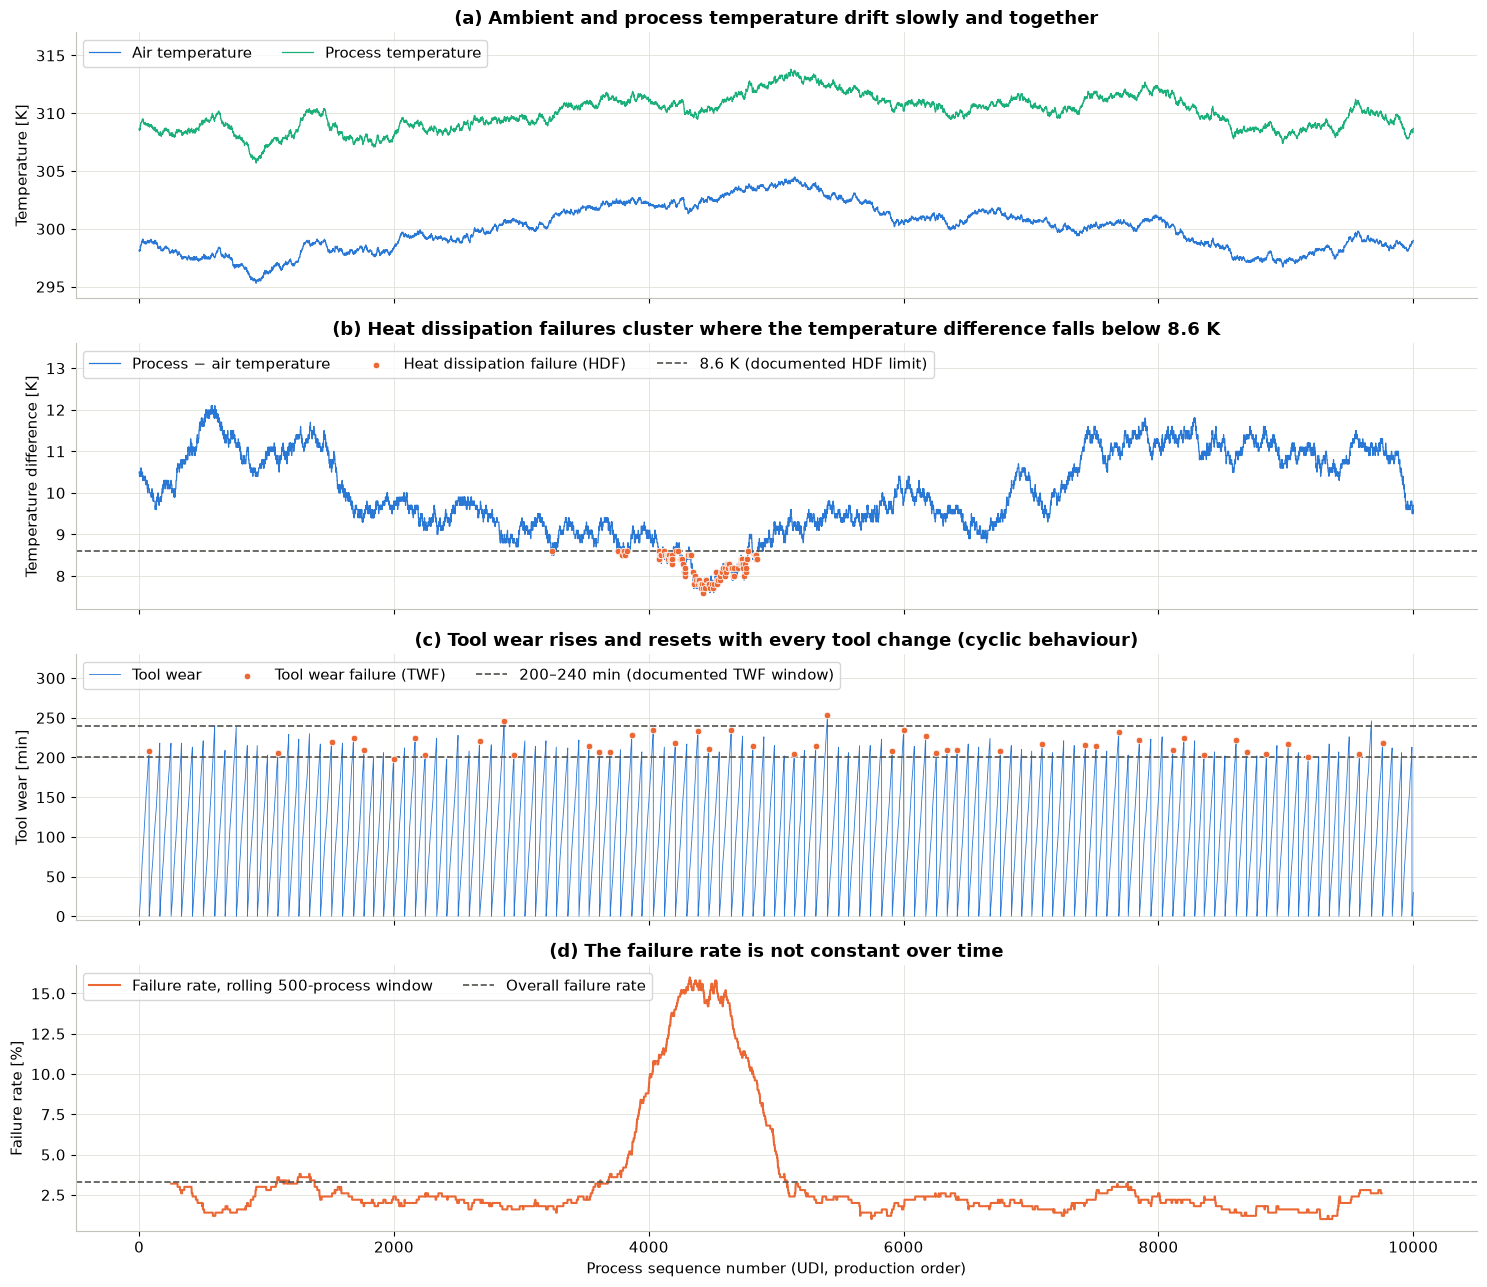

Air temperature range           : 295.3 – 304.5 K
Temperature difference range    : 7.6 – 12.1 K
Lag-1 autocorrelation of ΔT     : 0.9975  (1 = changes very slowly)
Tool changes (wear resets)      : 119
Tool wear at tool-wear failures : 198 – 253 min
Rolling failure rate            : 1.0 % – 16.0 %  (overall 3.3%)


In [20]:
seq = df_clean["udi"]
temp_diff = df_clean["process_temp_k"] - df_clean["air_temp_k"]
WINDOW = 500   # processes per rolling window

fig, axes = plt.subplots(4, 1, figsize=(15, 13), sharex=True)

# (a) Ambient and process temperature
axes[0].plot(seq, df_clean["air_temp_k"], color=COLOR_OK, linewidth=0.9, label="Air temperature")
axes[0].plot(seq, df_clean["process_temp_k"], color=COLOR_ALT, linewidth=0.9, label="Process temperature")
axes[0].set_ylim(294, 317)            # headroom above the data for the legend
axes[0].set_ylabel("Temperature [K]")
axes[0].set_title("(a) Ambient and process temperature drift slowly and together")
axes[0].legend(loc="upper left", ncol=2)

# (b) Temperature difference, with heat dissipation failures marked
hdf_rows = df_clean["hdf"] == 1
axes[1].plot(seq, temp_diff, color=COLOR_OK, linewidth=0.9, label="Process − air temperature")
axes[1].scatter(seq[hdf_rows], temp_diff[hdf_rows], color=COLOR_FAIL, s=22, zorder=3,
                edgecolor="white", linewidth=0.5, label="Heat dissipation failure (HDF)")
axes[1].axhline(8.6, color=COLOR_REF, linestyle="--", linewidth=1.2, label="8.6 K (documented HDF limit)")
axes[1].set_ylim(7.2, 13.6)            # headroom above the data for the legend
axes[1].set_ylabel("Temperature difference [K]")
axes[1].set_title("(b) Heat dissipation failures cluster where the temperature difference falls below 8.6 K")
axes[1].legend(loc="upper left", ncol=3)

# (c) Tool wear: a sawtooth, one tooth per tool life
twf_rows = df_clean["twf"] == 1
axes[2].plot(seq, df_clean["tool_wear_min"], color=COLOR_OK, linewidth=0.6, label="Tool wear")
axes[2].scatter(seq[twf_rows], df_clean.loc[twf_rows, "tool_wear_min"], color=COLOR_FAIL, s=22, zorder=3,
                edgecolor="white", linewidth=0.5, label="Tool wear failure (TWF)")
axes[2].axhline(200, color=COLOR_REF, linestyle="--", linewidth=1.2, label="200–240 min (documented TWF window)")
axes[2].axhline(240, color=COLOR_REF, linestyle="--", linewidth=1.2)
axes[2].set_ylim(-5, 330)              # headroom above the data for the legend
axes[2].set_ylabel("Tool wear [min]")
axes[2].set_title("(c) Tool wear rises and resets with every tool change (cyclic behaviour)")
axes[2].legend(loc="upper left", ncol=3)

# (d) Rolling failure rate
rolling_rate = df_clean["machine_failure"].rolling(WINDOW, center=True).mean() * 100
axes[3].plot(seq, rolling_rate, color=COLOR_FAIL, linewidth=1.5, label=f"Failure rate, rolling {WINDOW}-process window")
axes[3].axhline(df_clean["machine_failure"].mean() * 100, color=COLOR_REF, linestyle="--", linewidth=1.2,
                label="Overall failure rate")
axes[3].set_ylabel("Failure rate [%]")
axes[3].set_xlabel("Process sequence number (UDI, production order)")
axes[3].set_title("(d) The failure rate is not constant over time")
axes[3].legend(loc="upper left", ncol=2)

plt.tight_layout()
plt.show()

# Numbers behind the figure
tool_changes = int((df_clean["tool_wear_min"].diff() < 0).sum())
print(f"Air temperature range           : {df_clean['air_temp_k'].min():.1f} – {df_clean['air_temp_k'].max():.1f} K")
print(f"Temperature difference range    : {temp_diff.min():.1f} – {temp_diff.max():.1f} K")
print(f"Lag-1 autocorrelation of ΔT     : {temp_diff.autocorr(1):.4f}  (1 = changes very slowly)")
print(f"Tool changes (wear resets)      : {tool_changes}")
print(f"Tool wear at tool-wear failures : {df_clean.loc[twf_rows, 'tool_wear_min'].min()} – {df_clean.loc[twf_rows, 'tool_wear_min'].max()} min")
print(f"Rolling failure rate            : {rolling_rate.min():.1f} % – {rolling_rate.max():.1f} %  (overall {df_clean['machine_failure'].mean():.1%})")

**Interpretation (trend, variability, cyclic behaviour).**

* **Trend / slow drift (a).** Ambient temperature wanders slowly over a range of about 9 K, like a workshop warming and cooling through the day or the season, and the process temperature follows it. There is no regular repeating (seasonal) pattern, and without clock times we could not identify a daily or yearly cycle anyway.
* **Variability that matters (b).** The *gap* between process and air temperature changes very slowly too (lag-1 autocorrelation close to 1). Heat dissipation failures happen only in the stretches where this gap drops below the documented 8.6 K, so **they arrive in clusters** rather than at random.
* **Cyclic behaviour (c).** Tool wear is a sawtooth with about 120 cycles. Each tooth is one tool's life: it wears from 0 to roughly 200–250 min and is then replaced. Tool-wear failures sit at the top of the teeth, inside the documented 200–240 min window.
* **Non-constant risk (d).** The rolling failure rate swings between about 1 % and 16 %, compared with 3.3 % overall. **Failure risk depends on when you look**, mainly because of the heat-related clusters. This matters for model testing: in Section 6.13 we also test a model trained on *earlier* processes and evaluated on *later* ones.

### 3.6 Operating map: speed vs torque with constant-power curves

Mechanical power is $P = \tau\,\omega$ with $\omega = 2\pi n / 60$ (rpm converted to rad/s). For a fixed power $P$, the curve $\tau = P/\omega$ is a hyperbola in the speed–torque plane. We draw the two documented power limits, 3,500 W and 9,000 W.

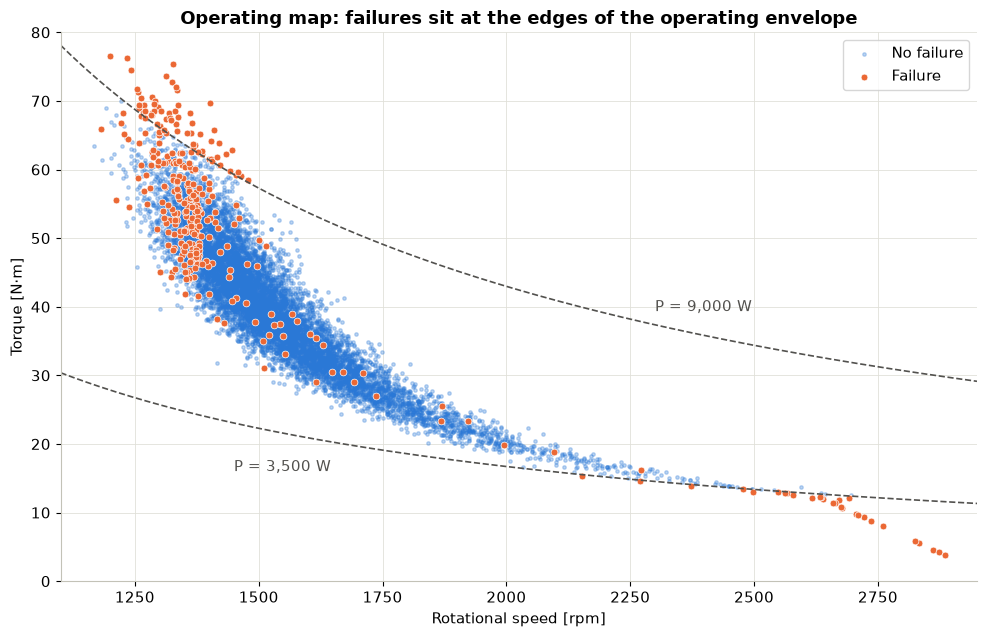

In [21]:
normal = df_clean["machine_failure"] == 0
rpm_grid = np.linspace(1100, 2950, 300)          # speeds for the constant-power curves [rpm]
omega_grid = rpm_grid * 2 * np.pi / 60           # the same speeds in rad/s

plt.figure(figsize=(10, 6.5))
plt.scatter(df_clean.loc[normal, "rot_speed_rpm"], df_clean.loc[normal, "torque_nm"],
            s=6, alpha=0.3, color=COLOR_OK, label="No failure")
plt.scatter(df_clean.loc[~normal, "rot_speed_rpm"], df_clean.loc[~normal, "torque_nm"],
            s=24, color=COLOR_FAIL, edgecolor="white", linewidth=0.5, label="Failure")

# Constant-power curves: torque = power / angular speed
# (each label sits at a speed where the area next to the curve is empty: above it for 9,000 W, below it for 3,500 W)
for power_w, label_rpm, offset in [(3500, 1450, -7.0), (9000, 2300, 2.0)]:
    plt.plot(rpm_grid, power_w / omega_grid, color=COLOR_REF, linestyle="--", linewidth=1.2)
    plt.text(label_rpm, power_w / (label_rpm * 2 * np.pi / 60) + offset, f"P = {power_w:,} W", color=COLOR_REF)

plt.ylim(0, 80)
plt.xlim(1100, 2950)
plt.xlabel("Rotational speed [rpm]")
plt.ylabel("Torque [N·m]")
plt.title("Operating map: failures sit at the edges of the operating envelope")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Interpretation.** The normal processes form a curved band that follows a constant-power hyperbola: the machine trades speed for torque. Failures are concentrated at the **edges** of this band:

* **above the 9,000 W curve:** high torque at moderate speed, which overloads the drive (power failure);
* **below the 3,500 W curve:** very low torque at high speed (power failure at the low end). This is the low-torque failure group seen in the torque histogram;
* **high torque in general** (overstrain, especially when the tool is worn) and **low speed** (heat dissipation, when cooling is weak).

No single sensor variable separates these regions, but **combinations** of them (power, wear × torque, temperature difference with speed) do. This is the main motivation for the feature engineering in Section 5.

### 3.7 Failure rate by product quality variant

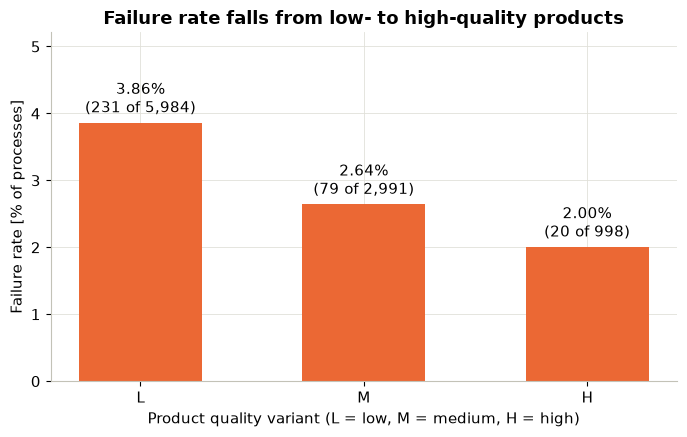

,mean,sum,count
type,,,
L,0.038603,231,5984
M,0.026413,79,2991
H,0.020040,20,998


In [22]:
rate_by_type = (df_clean.groupby("type")["machine_failure"]
                .agg(["mean", "sum", "count"])
                .reindex(["L", "M", "H"]))

plt.figure(figsize=(7, 4.5))
plt.bar(rate_by_type.index, rate_by_type["mean"] * 100, color=COLOR_FAIL, width=0.55)
for i, (rate, n_fail, n_total) in enumerate(zip(rate_by_type["mean"], rate_by_type["sum"], rate_by_type["count"])):
    plt.text(i, rate * 100 + 0.08, f"{rate:.2%}\n({n_fail} of {n_total:,})", ha="center", va="bottom")
plt.ylim(0, rate_by_type["mean"].max() * 100 * 1.35)
plt.xlabel("Product quality variant (L = low, M = medium, H = high)")
plt.ylabel("Failure rate [% of processes]")
plt.title("Failure rate falls from low- to high-quality products")
plt.tight_layout()
plt.show()

rate_by_type

**Interpretation.** The failure rate falls steadily from **L (3.86 %)** through **M (2.64 %)** to **H (2.00 %)**: low-quality products fail almost twice as often as high-quality ones. Whether this difference is larger than chance would produce, and *why* it exists, are tested formally in Sections 4.2 and 4.3.

### 3.8 EDA summary

| Observation | Engineering meaning |
|---|---|
| 3.3 % failures | Accuracy is misleading; use recall/precision/F1 and a stratified split |
| Failures at high torque *and* very low torque | Two different mechanisms (overload vs low-power); one torque limit is not enough |
| Failures at high tool wear (> 200 min) | Tool end-of-life is a failure driver |
| Speed–torque $r = -0.88$ | The machine runs near constant power, $P = \tau\omega$ |
| Weak linear correlations with failure | Failures are threshold effects → engineered features, tree models |
| HDF failures cluster in time; rolling rate 1–16 % | Ambient conditions change the risk over time |
| L fails ≈ 2× as often as H | The product variant matters (tested in 4.2–4.3) |

## 4. Statistical Inference & Hypothesis Testing

Each test follows the course's six-step hypothesis-testing template:

1. Identify the key question → 2. Establish $H_0$ and $H_1$ → 3. Understand and prepare the data → 4. Identify the right test → 5. Check the assumptions → 6. Perform the test and conclude using the p-value.

The **significance level** is $\alpha = 0.05$ for each test: we reject $H_0$ when $p < 0.05$. Test choice follows the course flowchart for choosing a statistical test:

| Predictor | Outcome | Test | Used in |
|---|---|---|---|
| categorical, 2 groups (failure yes/no) | quantitative (torque) | two-sample **t-test** | 4.1 |
| categorical (type) | categorical (failure yes/no) | **chi-square** test of independence | 4.2 |
| categorical, 3 groups (type L/M/H) | quantitative (torque) | one-way **ANOVA** | 4.3 |

We also report an **effect size** for each test. With almost 10,000 observations even tiny differences can be "statistically significant", so the effect size tells us whether a difference is large enough to matter in engineering terms.

### 4.1 Test 1: Do failed processes run at a different torque? (two-sample t-test)

**Step 1, key question.** Is the mean torque of processes that fail different from that of processes that do not fail? (Analytical question Q1.)

**Step 2, hypotheses.** With $\mu_F$ the mean torque of failed processes and $\mu_N$ that of normal processes:

$$H_0: \mu_F = \mu_N \qquad \text{vs.} \qquad H_1: \mu_F \neq \mu_N \quad \text{(two-tailed)}$$

The test is two-tailed because, before looking at the test result, failure could plausibly come with *either* higher torque (overload) *or* lower torque.

**Step 3, data.** Torque values of the 330 failed and 9,643 normal processes. Each process is a separate job, so the two groups are independent.

In [23]:
# Step 3: the two independent samples
torque_fail = df_clean.loc[df_clean["machine_failure"] == 1, "torque_nm"]
torque_ok = df_clean.loc[df_clean["machine_failure"] == 0, "torque_nm"]
print(f"Failed processes : n = {len(torque_fail):>5,}   mean = {torque_fail.mean():.2f} N·m   std = {torque_fail.std():.2f} N·m")
print(f"Normal processes : n = {len(torque_ok):>5,}   mean = {torque_ok.mean():.2f} N·m   std = {torque_ok.std():.2f} N·m")

Failed processes : n =   330   mean = 50.40 N·m   std = 16.46 N·m
Normal processes : n = 9,643   mean = 39.62 N·m   std = 9.47 N·m


**Step 4, test choice.** One categorical predictor with two groups and a quantitative outcome → **two-sample (independent) t-test**.

**Step 5, assumptions.**

* *Independence*: satisfied by design (different processes).
* *Normality* (Shapiro–Wilk test, $H_0$: the data are normal). Shapiro–Wilk is designed for small and medium samples; with thousands of points it flags even trivial deviations. For the large normal group we therefore test a random sample of 500 processes (fixed seed).
* *Equal variances* (Levene test, $H_0$: the two groups have equal variance).

In [24]:
# Step 5a: normality of each group (Shapiro-Wilk)
w_fail, p_norm_fail = stats.shapiro(torque_fail)
w_ok, p_norm_ok = stats.shapiro(torque_ok.sample(500, random_state=RANDOM_STATE))
print(f"Shapiro-Wilk, failed group (n = {len(torque_fail)})  : W = {w_fail:.3f}, p = {p_norm_fail:.2e}")
print(f"Shapiro-Wilk, normal group (sample of 500)  : W = {w_ok:.3f}, p = {p_norm_ok:.3f}")

# Step 5b: equality of variances (Levene)
levene_stat, p_levene = stats.levene(torque_fail, torque_ok)
print(f"Levene test for equal variances             : W = {levene_stat:.1f}, p = {p_levene:.2e}")

Shapiro-Wilk, failed group (n = 330)  : W = 0.874, p = 8.23e-16
Shapiro-Wilk, normal group (sample of 500)  : W = 0.997, p = 0.387
Levene test for equal variances             : W = 144.9, p = 3.90e-33


**Assumption check results.**

* The normal group is consistent with a normal distribution ($p > 0.05$). The failed group is **not** normal ($p \ll 0.05$), which is expected because its torque distribution is bimodal (Section 3.2). The t-test compares **means**, however, and by the **Central Limit Theorem** the mean of 330 observations is approximately normally distributed whatever the shape of the data. With samples this large, the t-test is robust to non-normal data.
* Levene's test rejects equal variances ($p \ll 0.05$): the failed group's torque is spread out much more widely. We therefore use **Welch's t-test** (`equal_var=False`), the version of the two-sample t-test that does **not** assume equal variances.

**Step 6, perform the test.**

In [25]:
# Step 6: Welch's two-sample t-test
ttest_result = stats.ttest_ind(torque_fail, torque_ok, equal_var=False)
t_stat, p_value = ttest_result.statistic, ttest_result.pvalue
welch_df = ttest_result.df                     # Welch-Satterthwaite degrees of freedom

# 95 % confidence interval for the difference in means (Welch standard error)
mean_diff = torque_fail.mean() - torque_ok.mean()
std_error = np.sqrt(torque_fail.var() / len(torque_fail) + torque_ok.var() / len(torque_ok))
t_critical = stats.t.ppf(0.975, welch_df)
ci_low, ci_high = mean_diff - t_critical * std_error, mean_diff + t_critical * std_error

# Effect size: Cohen's d = difference in means / pooled standard deviation
n_f, n_n = len(torque_fail), len(torque_ok)
pooled_sd = np.sqrt(((n_f - 1) * torque_fail.var() + (n_n - 1) * torque_ok.var()) / (n_f + n_n - 2))
cohens_d = mean_diff / pooled_sd

print(f"t statistic              : {t_stat:.2f}  (degrees of freedom = {welch_df:.1f})")
print(f"p-value (two-tailed)     : {p_value:.2e}")
print(f"Difference in means      : {mean_diff:.2f} N·m  (95 % CI {ci_low:.2f} to {ci_high:.2f} N·m)")
print(f"Relative difference      : {mean_diff / torque_ok.mean():.1%} higher torque in failed processes")
print(f"Cohen's d (effect size)  : {cohens_d:.2f}")
print("Decision at alpha = 0.05 :", "reject H0" if p_value < 0.05 else "fail to reject H0")

t statistic              : 11.83  (degrees of freedom = 336.5)
p-value (two-tailed)     : 3.12e-27
Difference in means      : 10.78 N·m  (95 % CI 8.98 to 12.57 N·m)
Relative difference      : 27.2% higher torque in failed processes
Cohen's d (effect size)  : 1.10
Decision at alpha = 0.05 : reject H0


**Conclusion.** $t = 11.8$ with $p \approx 3 \times 10^{-27} < 0.05$, so we **reject $H_0$**. Failed processes run at a mean torque about **10.8 N·m higher** (95 % confidence interval roughly 9.0 to 12.6 N·m), about **27 % more mechanical load** than normal processes. Cohen's $d \approx 1.1$ is a *large* effect (by the usual rule of thumb, 0.2 is small, 0.5 medium and 0.8 large).

**Engineering meaning.** Mechanical load is a major driver of failure, consistent with the overstrain and power-overload mechanisms. But the test answers only a question about the **average**. Section 3 showed that some failures happen at *very low* torque, so an alarm on high torque alone would miss them. This is why Section 5 combines torque with speed (power) and with tool wear.

#### Supporting analysis: the same test for all five sensors

We repeat Welch's t-test for each sensor. Running five tests raises the chance that at least one is "significant" by luck, so we apply the **Bonferroni correction**: each test must reach $p < 0.05 / 5 = 0.01$.

In [26]:
# Welch's t-test for every sensor variable, with a Bonferroni-corrected threshold
alpha_bonferroni = 0.05 / len(SENSOR_COLS)
ttest_rows = []
for col in SENSOR_COLS:
    fail_values = df_clean.loc[df_clean["machine_failure"] == 1, col]
    ok_values = df_clean.loc[df_clean["machine_failure"] == 0, col]
    result = stats.ttest_ind(fail_values, ok_values, equal_var=False)
    ttest_rows.append({
        "variable": LABELS[col],
        "mean_failure": round(fail_values.mean(), 2),
        "mean_no_failure": round(ok_values.mean(), 2),
        "difference": round(fail_values.mean() - ok_values.mean(), 2),
        "t_statistic": round(result.statistic, 2),
        "p_value": result.pvalue,
        f"significant (p < {alpha_bonferroni})": result.pvalue < alpha_bonferroni,
    })
ttest_table = pd.DataFrame(ttest_rows)
ttest_table

,variable,mean_failure,mean_no_failure,difference,t_statistic,p_value,significant (p < 0.01)
0,Air temperature [K],300.90,299.97,0.93,8.01,1.666506e-14,True
1,Process temperature [K],310.29,309.99,0.30,3.88,1.223230e-04,True
2,Rotational speed [rpm],1496.18,1540.35,-44.17,-2.05,4.083101e-02,False
3,Torque [N·m],50.40,39.62,10.78,11.83,3.123921e-27,True
4,Tool wear [min],144.51,106.67,37.84,9.31,1.565694e-18,True


**Interpretation.** Failed processes have significantly higher torque, **higher tool wear (about 38 min more)**, and slightly higher air and process temperatures. **Rotational speed is *not* significant** after the correction ($p \approx 0.04 > 0.01$), even though Section 3 showed that speed matters a great deal: failures occur at both *low* speed (heat dissipation) and *high* speed (low-power failures), so the two effects cancel in the average. **"No difference in means" is not the same as "no relationship".** A t-test only detects a *shift* of the average.

### 4.2 Test 2: Does failure depend on the product variant? (chi-square test of independence)

**Step 1, key question.** Is the probability of failure the same for L, M and H products? (Analytical question Q2.)

**Step 2, hypotheses.**

* $H_0$: machine failure is **independent** of product type (the failure rate is the same for L, M and H).
* $H_1$: machine failure **depends on** product type.

**Step 3, data.** A contingency table of product type × outcome.

**Step 4, test choice.** Two categorical variables → **chi-square ($\chi^2$) test of independence**. It compares the observed counts with the counts *expected* if $H_0$ were true.

**Step 5, assumptions.** Observations are independent (separate processes), and every *expected* cell count should be at least 5.

In [27]:
# Step 3: observed contingency table
contingency = pd.crosstab(df_clean["type"], df_clean["status"]).reindex(index=["L", "M", "H"], columns=STATUS_ORDER)
print("Observed counts:")
print(contingency)

# Steps 5-6: chi-square test of independence
chi2_stat, p_chi2, dof, expected = stats.chi2_contingency(contingency)
expected_table = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns).round(1)
print("\nExpected counts if H0 were true:")
print(expected_table)
print(f"\nSmallest expected count : {expected.min():.1f}  (assumption: at least 5)")
print(f"Chi-square statistic    : {chi2_stat:.2f}  (degrees of freedom = {dof})")
print(f"p-value                 : {p_chi2:.5f}")
print("Decision at alpha = 0.05:", "reject H0" if p_chi2 < 0.05 else "fail to reject H0")

# Effect size: Cramér's V (0 = no association, 1 = perfect association)
n_total = contingency.values.sum()
cramers_v = np.sqrt(chi2_stat / (n_total * (min(contingency.shape) - 1)))
rates = contingency["Failure"] / contingency.sum(axis=1)
print(f"Cramér's V              : {cramers_v:.3f}")
print(f"Failure rate L / M / H  : {rates['L']:.2%} / {rates['M']:.2%} / {rates['H']:.2%}")
print(f"Risk ratio L vs H       : {rates['L'] / rates['H']:.2f}")

Observed counts:
status  No failure  Failure
type                       
L             5753      231
M             2912       79
H              978       20

Expected counts if H0 were true:
status  No failure  Failure
type                       
L           5786.0    198.0
M           2892.0     99.0
H            965.0     33.0

Smallest expected count : 33.0  (assumption: at least 5)
Chi-square statistic    : 15.16  (degrees of freedom = 2)
p-value                 : 0.00051
Decision at alpha = 0.05: reject H0
Cramér's V              : 0.039
Failure rate L / M / H  : 3.86% / 2.64% / 2.00%
Risk ratio L vs H       : 1.93


**Conclusion.** All expected counts are far above 5, so the test is valid. $\chi^2 = 15.2$ with 2 degrees of freedom and $p \approx 0.0005 < 0.05$: we **reject $H_0$**. Failure **does depend on the product variant**: L-variant processes fail at 3.86 %, about **1.9 times as often** as H-variant processes (2.00 %).

**Engineering meaning.** The effect is real but **small** (Cramér's $V \approx 0.04$, and the gap between L and H is under 2 percentage points). Product type alone is a weak predictor of failure; operating conditions matter far more. That raises a follow-up question: are L products failing more because they are machined *harder*, or because the product itself is less tolerant? Test 3 answers this.

### 4.3 Test 3: Are the variants machined under the same load? (one-way ANOVA)

**Step 1, key question.** Is the mean torque the same for L, M and H processes? If L products were machined with more torque, that could explain their higher failure rate.

**Step 2, hypotheses.**

$$H_0: \mu_L = \mu_M = \mu_H \qquad \text{vs.} \qquad H_1: \text{at least one mean torque differs}$$

**Step 3, data.** Torque values grouped by product type.

**Step 4, test choice.** One categorical predictor with three groups and a quantitative outcome → **one-way ANOVA** (analysis of variance). ANOVA compares the variation *between* the group means with the variation *within* the groups (the $F$ statistic).

**Step 5, assumptions.** Independence (separate processes), approximately normal data in each group (Shapiro–Wilk on samples of 500), and equal variances across groups (Levene).

In [28]:
# Step 3: torque of each product type
torque_L = df_clean.loc[df_clean["type"] == "L", "torque_nm"]
torque_M = df_clean.loc[df_clean["type"] == "M", "torque_nm"]
torque_H = df_clean.loc[df_clean["type"] == "H", "torque_nm"]

# Step 5a: normality in each group (Shapiro-Wilk on a random sample of 500 per group)
for name, values in [("L", torque_L), ("M", torque_M), ("H", torque_H)]:
    w_stat, p_norm = stats.shapiro(values.sample(500, random_state=RANDOM_STATE))
    print(f"Type {name}: n = {len(values):>5,}  mean = {values.mean():.2f} N·m  std = {values.std():.2f} N·m  Shapiro p = {p_norm:.3f}")

# Step 5b: equal variances across the three groups (Levene)
levene_types = stats.levene(torque_L, torque_M, torque_H)
print(f"\nLevene test across types: W = {levene_types.statistic:.2f}, p = {levene_types.pvalue:.3f}")

Type L: n = 5,984  mean = 39.99 N·m  std = 10.01 N·m  Shapiro p = 0.619
Type M: n = 2,991  mean = 40.01 N·m  std = 9.99 N·m  Shapiro p = 0.173
Type H: n =   998  mean = 39.83 N·m  std = 9.64 N·m  Shapiro p = 0.356

Levene test across types: W = 0.74, p = 0.478


All three groups are consistent with normality (Shapiro $p > 0.05$) and with equal variances (Levene $p \approx 0.48$), so the ANOVA assumptions hold.

**Step 6, perform the test** (using statsmodels, as in the course ANOVA material).

In [29]:
# Step 6: one-way ANOVA via a linear model (statsmodels)
anova_model = ols("torque_nm ~ type", data=df_clean).fit()
anova_table = sm.stats.anova_lm(anova_model, typ=1)
print(anova_table)

p_anova = anova_table.loc["type", "PR(>F)"]
print("\nDecision at alpha = 0.05:", "reject H0" if p_anova < 0.05 else "fail to reject H0")

              df         sum_sq    mean_sq         F    PR(>F)
type         2.0      27.058609  13.529305  0.136172  0.872694
Residual  9970.0  990563.490483  99.354412       NaN       NaN

Decision at alpha = 0.05: fail to reject H0


$F = 0.14$ with $p \approx 0.87 > 0.05$: we **fail to reject $H_0$**. There is no evidence that mean torque differs between the variants.

A non-significant result does *not* prove the means are exactly equal, so we also look at how large any difference *could* be. Tukey's HSD test (the course's post-hoc test) gives a confidence interval for each pairwise difference:

In [30]:
# Tukey HSD: 95 % family-wise confidence intervals for every pairwise difference in mean torque
tukey = MultiComparison(df_clean["torque_nm"], df_clean["type"]).tukeyhsd()
print(tukey.summary())

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     H      L   0.1596 0.8862 -0.6393 0.9585  False
     H      M    0.187  0.865 -0.6672 1.0411  False
     L      M   0.0273 0.9918 -0.4959 0.5506  False
---------------------------------------------------


In [31]:
# Supporting check: the same one-way ANOVA for the other operating variables
anova_rows = []
for col in ["rot_speed_rpm", "tool_wear_min", "air_temp_k", "process_temp_k"]:
    model = ols(f"{col} ~ type", data=df_clean).fit()
    table = sm.stats.anova_lm(model, typ=1)
    anova_rows.append({
        "variable": LABELS[col],
        "F_statistic": round(table.loc["type", "F"], 3),
        "p_value": round(table.loc["type", "PR(>F)"], 3),
        "significant at 0.05": table.loc["type", "PR(>F)"] < 0.05,
    })
pd.DataFrame(anova_rows)

,variable,F_statistic,p_value,significant at 0.05
0,Rotational speed [rpm],0.117,0.890,False
1,Tool wear [min],0.259,0.772,False
2,Air temperature [K],2.725,0.066,False
3,Process temperature [K],1.690,0.185,False


**Conclusion and engineering meaning.** Every pairwise interval contains zero and is narrow: any true difference in mean torque between variants is at most about **1 N·m (under 3 % of the mean torque)**, negligible for the machine. The supporting ANOVAs find no significant difference for speed, tool wear or either temperature either (all $p > 0.05$; air temperature comes closest at $p \approx 0.07$). **All three variants are machined under the same operating conditions.**

Combining Tests 2 and 3: L products fail more often **although they are not machined harder**, so the difference must come from the **product variant itself**. This agrees with the dataset documentation, where the overstrain limit is lower for L (11,000 min·N·m) than for M (12,000) and H (13,000). The practical consequence is to use **stricter tool-wear or torque limits for L-variant jobs** rather than changing how the machine is run.

### 4.4 Summary of statistical findings

| Test | $H_0$ | Statistic | p-value | Decision | Effect size | Engineering meaning |
|---|---|---|---|---|---|---|
| Welch t-test: torque, failed vs normal | equal mean torque | $t = 11.8$ | $3 \times 10^{-27}$ | reject $H_0$ | $d = 1.1$ (large) | failed processes run ≈ 11 N·m (27 %) higher load |
| χ² test: type × failure | failure independent of type | $\chi^2 = 15.2$ | $0.0005$ | reject $H_0$ | $V = 0.04$ (small) | L fails ≈ 1.9× as often as H |
| One-way ANOVA: torque across L/M/H | equal mean torque | $F = 0.14$ | $0.87$ | fail to reject | differences < 1 N·m | variants run under the same load → the variant itself is less tolerant |

## 5. Feature Engineering

### 5.1 New features and their physical meaning

The EDA showed that failures depend on **combinations** of sensor values. We create three features that combine them the way physics does:

| Feature | Formula | Unit | Engineering reason |
|---|---|---|---|
| Temperature difference | $\Delta T = T_\mathrm{process} - T_\mathrm{air}$ | K | Heat leaves the process at a rate roughly proportional to the temperature gradient (Newton's law of cooling, $\dot{Q} = hA\,\Delta T$). A **small $\Delta T$** means the heat is not being removed, especially at low spindle speed, when there is less air movement. |
| Mechanical power | $P = \tau\,\omega$, with $\omega = \dfrac{2\pi n}{60}$ | W | The power the spindle drive must deliver. A drive is designed for a **power window**: too little power means it is not cutting properly, too much overloads it. Speed in rpm ($n$) must first be converted to rad/s ($\omega$). |
| Tool wear × torque ("strain") | $S = t_\mathrm{wear}\cdot\tau$ | min·N·m | A worn tool is weaker, and torque is the load on it. Their product measures how much **load a degraded tool is carrying**: a simple proxy for accumulated strain or fatigue damage. |

The product type is a text category, so it is **one-hot encoded** later (Section 5.4).

**Why no rolling averages or frequency-domain features?** The project brief suggests these for signal data. They do not fit this dataset: each row is an *independent process snapshot*, not a sampled waveform, so there is no signal to transform into frequencies. A rolling average across rows would mix different jobs and blur the extreme values that indicate failure, and when the data are randomly split into training and test sets it would also carry information from test rows into training rows (*data leakage*). We used a rolling average only to *visualise* slow trends (Section 3.5).

In [32]:
# 5.1 Physically motivated features
omega_rad_s = df_clean["rot_speed_rpm"] * 2 * np.pi / 60             # rpm -> rad/s
df_clean["temp_diff_k"] = df_clean["process_temp_k"] - df_clean["air_temp_k"]
df_clean["power_w"] = df_clean["torque_nm"] * omega_rad_s             # P = torque x angular speed
df_clean["strain_minnm"] = df_clean["tool_wear_min"] * df_clean["torque_nm"]

ENGINEERED_COLS = ["temp_diff_k", "power_w", "strain_minnm"]
df_clean[ENGINEERED_COLS].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
temp_diff_k,9973.0,10.0,1.0,7.6,9.3,9.8,11.0,12.1
power_w,9973.0,6278.9,1067.0,1148.4,5561.8,6269.2,7001.5,10469.9
strain_minnm,9973.0,4313.0,2826.2,0.0,1963.7,4006.8,6276.4,16497.0


The machine typically runs at about **6.3 kW** (mean power), and the temperature difference stays between 7.6 and 12.1 K.

### 5.2 Check: do the features capture the documented failure physics?

The dataset documentation states the conditions under which HDF, PWF and OSF occur. If our features (and our unit conversions) are right, applying these conditions should reproduce the failure flags in the data. **The documented limits are used here only to validate the features. They are not given to the models,** which must learn the thresholds from data (Section 6.10 shows that they do).

In [33]:
# Documented failure conditions, written with our engineered features
overstrain_limit = df_clean["type"].map({"L": 11000, "M": 12000, "H": 13000})   # min·N·m, by variant
rule_hdf = (df_clean["temp_diff_k"] < 8.6) & (df_clean["rot_speed_rpm"] < 1380)
rule_pwf = (df_clean["power_w"] < 3500) | (df_clean["power_w"] > 9000)
rule_osf = df_clean["strain_minnm"] > overstrain_limit

rule_check = pd.DataFrame({
    "documented_condition": ["HDF: ΔT < 8.6 K and speed < 1,380 rpm",
                             "PWF: power < 3,500 W or > 9,000 W",
                             "OSF: wear × torque > 11,000 / 12,000 / 13,000 min·N·m (L / M / H)"],
    "rows_meeting_condition": [rule_hdf.sum(), rule_pwf.sum(), rule_osf.sum()],
    "rows_flagged_in_data": [df_clean["hdf"].sum(), df_clean["pwf"].sum(), df_clean["osf"].sum()],
    "row_by_row_agreement_%": [(rule_hdf == (df_clean["hdf"] == 1)).mean() * 100,
                               (rule_pwf == (df_clean["pwf"] == 1)).mean() * 100,
                               (rule_osf == (df_clean["osf"] == 1)).mean() * 100],
})
print(rule_check.to_string(index=False))

# Do any of the 27 removed (contradictory) rows meet a documented condition?
removed_temp_diff = removed_rows["process_temp_k"] - removed_rows["air_temp_k"]
removed_power = removed_rows["torque_nm"] * removed_rows["rot_speed_rpm"] * 2 * np.pi / 60
removed_strain = removed_rows["tool_wear_min"] * removed_rows["torque_nm"]
removed_limit = removed_rows["type"].map({"L": 11000, "M": 12000, "H": 13000})
removed_meets_rule = (((removed_temp_diff < 8.6) & (removed_rows["rot_speed_rpm"] < 1380))
                      | (removed_power < 3500) | (removed_power > 9000)
                      | (removed_strain > removed_limit))
print(f"\nRemoved rows meeting any documented HDF/PWF/OSF condition: {removed_meets_rule.sum()} of {len(removed_rows)}")

                                             documented_condition  rows_meeting_condition  rows_flagged_in_data  row_by_row_agreement_%
                            HDF: ΔT < 8.6 K and speed < 1,380 rpm                     115                   115                   100.0
                                PWF: power < 3,500 W or > 9,000 W                      95                    95                   100.0
OSF: wear × torque > 11,000 / 12,000 / 13,000 min·N·m (L / M / H)                      98                    98                   100.0

Removed rows meeting any documented HDF/PWF/OSF condition: 0 of 27


**Result: 100 % agreement on every row for all three mechanisms.** This confirms that the unit conversion is right (rpm → rad/s in the power formula) and that the engineered features are *exactly* the physical quantities these failures depend on. None of the 27 removed rows meets any of these conditions, which supports the decision in Section 2.6 to treat them as unreliable labels.

*A note on fairness:* we can confirm the rules this precisely only because the data are synthetic and the generator is documented. The **features themselves**, though, come from general engineering knowledge (power = torque × speed, heat flow ∝ temperature difference, load on a worn tool) that an engineer would bring to a real machine as well. The **exact thresholds** are specific to this simulated machine.

### 5.3 Visual check: the engineered features separate the failures

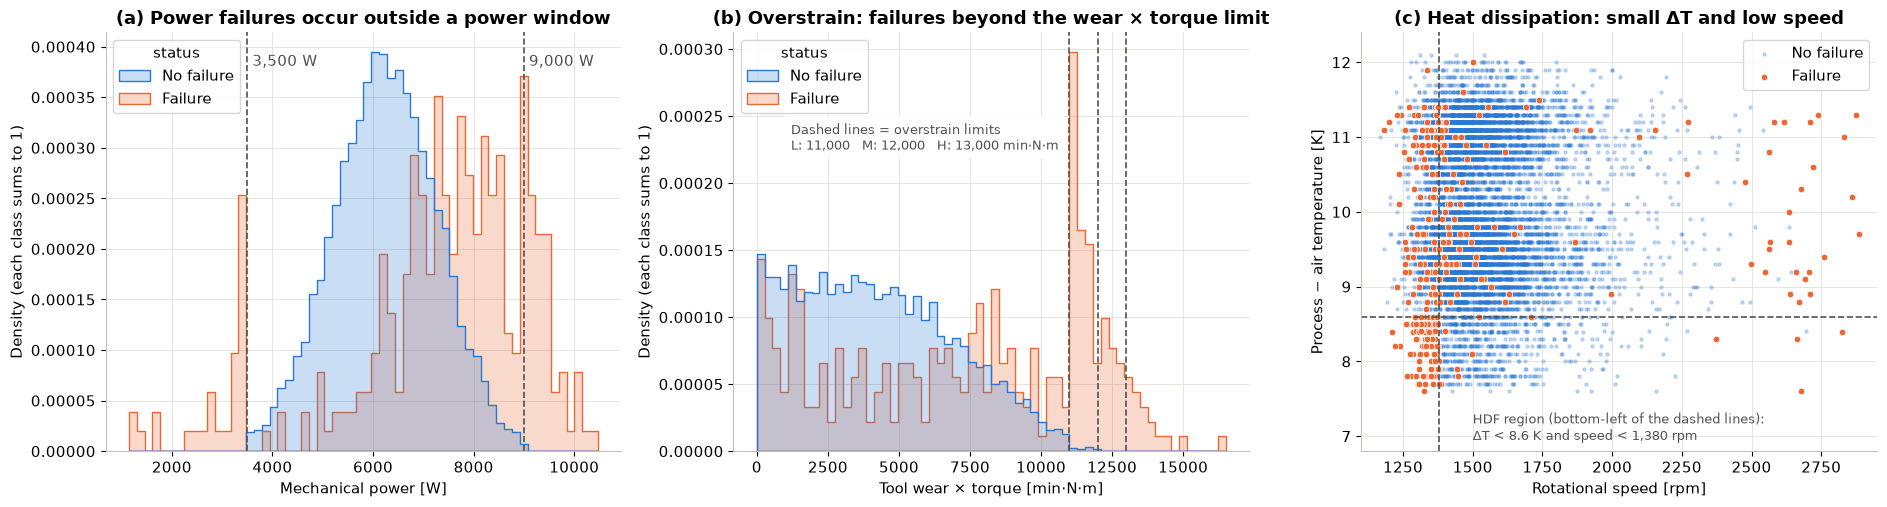

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))

# (a) Mechanical power, with the documented power window
sns.histplot(data=df_clean, x="power_w", hue="status", hue_order=STATUS_ORDER, palette=STATUS_PALETTE,
             stat="density", common_norm=False, bins=60, element="step", ax=axes[0])
for limit in [3500, 9000]:
    axes[0].axvline(limit, color=COLOR_REF, linestyle="--", linewidth=1.2)
axes[0].text(3500, axes[0].get_ylim()[1] * 0.92, " 3,500 W", color=COLOR_REF)
axes[0].text(9000, axes[0].get_ylim()[1] * 0.92, " 9,000 W", color=COLOR_REF)
axes[0].set_title("(a) Power failures occur outside a power window")
axes[0].set_xlabel(LABELS["power_w"])
axes[0].set_ylabel("Density (each class sums to 1)")

# (b) Tool wear x torque, with the documented overstrain limits per variant
sns.histplot(data=df_clean, x="strain_minnm", hue="status", hue_order=STATUS_ORDER, palette=STATUS_PALETTE,
             stat="density", common_norm=False, bins=60, element="step", ax=axes[1])
for limit in [11000, 12000, 13000]:
    axes[1].axvline(limit, color=COLOR_REF, linestyle="--", linewidth=1.2)
# One label in an empty part of the panel instead of three labels that collide with the bars
axes[1].text(1200, axes[1].get_ylim()[1] * 0.72,
             "Dashed lines = overstrain limits\nL: 11,000   M: 12,000   H: 13,000 min·N·m",
             color=COLOR_REF, fontsize=9, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
axes[1].set_title("(b) Overstrain: failures beyond the wear × torque limit")
axes[1].set_xlabel(LABELS["strain_minnm"])
axes[1].set_ylabel("Density (each class sums to 1)")

# (c) Temperature difference vs speed, with the documented heat-dissipation region
normal = df_clean["machine_failure"] == 0
axes[2].scatter(df_clean.loc[normal, "rot_speed_rpm"], df_clean.loc[normal, "temp_diff_k"],
                s=5, alpha=0.25, color=COLOR_OK, label="No failure")
axes[2].scatter(df_clean.loc[~normal, "rot_speed_rpm"], df_clean.loc[~normal, "temp_diff_k"],
                s=22, color=COLOR_FAIL, edgecolor="white", linewidth=0.5, label="Failure")
axes[2].axhline(8.6, color=COLOR_REF, linestyle="--", linewidth=1.2)
axes[2].axvline(1380, color=COLOR_REF, linestyle="--", linewidth=1.2)
# The lowest ΔT in the data is 7.6 K, so the band below it is empty and holds the label
axes[2].text(1500, 6.95, "HDF region (bottom-left of the dashed lines):\nΔT < 8.6 K and speed < 1,380 rpm",
             color=COLOR_REF, fontsize=9)
axes[2].set_xlim(1100, 2950)
axes[2].set_ylim(6.8, 12.4)
axes[2].set_title("(c) Heat dissipation: small ΔT and low speed")
axes[2].set_xlabel(LABELS["rot_speed_rpm"])
axes[2].set_ylabel(LABELS["temp_diff_k"])
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

**Interpretation.** Compare these panels with the raw-sensor histograms in 3.2. In the raw variables the failure distribution overlapped heavily with the normal one; with the engineered features, **failures sit almost entirely beyond clear limits**: (a) outside the 3.5–9 kW power window, (b) above the wear × torque limit of the product variant, and (c) in the low-speed, low-ΔT corner. Section 6.8 measures how much these features improve the models.

### 5.4 Model-ready feature matrix

* The product type is **one-hot encoded** with `pd.get_dummies(..., drop_first=True)`. This creates `type_L` and `type_M` (0/1 columns); a process with both equal to 0 is type H, the *reference* category. Dropping one column avoids giving the model redundant information.
* **Excluded from the inputs:**
    * `udi` and `product_id`: identifiers with no physical meaning; a model could memorise them instead of learning physics.
    * `twf`, `hdf`, `pwf`, `osf`, `rnf`: these flags *define* the target (a process fails if any flag is 1). Giving them to the model would be **target leakage**: near-perfect scores on paper and a useless model in practice, because the cause of a failure is only known *after* it has happened.
    * `status`: the text version of the target.

In [35]:
# One-hot encode the product type (H becomes the reference category)
model_df = pd.get_dummies(df_clean, columns=["type"], drop_first=True, dtype=int)

FEATURES_RAW = ["air_temp_k", "process_temp_k", "rot_speed_rpm", "torque_nm", "tool_wear_min", "type_L", "type_M"]
FEATURES_ALL = FEATURES_RAW + ENGINEERED_COLS
TARGET = "machine_failure"

print("Model inputs :", FEATURES_ALL)
print("Not used     :", ["udi", "product_id"] + MODE_COLS + ["status"])
model_df[FEATURES_ALL + [TARGET]].head()

Model inputs : ['air_temp_k', 'process_temp_k', 'rot_speed_rpm', 'torque_nm', 'tool_wear_min', 'type_L', 'type_M', 'temp_diff_k', 'power_w', 'strain_minnm']
Not used     : ['udi', 'product_id', 'twf', 'hdf', 'pwf', 'osf', 'rnf', 'status']


,air_temp_k,process_temp_k,rot_speed_rpm,torque_nm,tool_wear_min,type_L,type_M,temp_diff_k,power_w,strain_minnm,machine_failure
0,298.1,308.6,1551,42.8,0,0,1,10.5,6951.590560,0.0,0
1,298.2,308.7,1408,46.3,3,1,0,10.5,6826.722724,138.9,0
2,298.1,308.5,1498,49.4,5,1,0,10.4,7749.387543,247.0,0
3,298.2,308.6,1433,39.5,7,1,0,10.4,5927.504659,276.5,0
4,298.2,308.7,1408,40.0,9,1,0,10.5,5897.816608,360.0,0


## 6. Machine Learning Modeling

### 6.1 Task

* **Type of problem:** binary **classification**: predict `machine_failure` (1 = the process fails) from the process readings.
* **Inputs:** five sensor variables, the product type (one-hot) and the three engineered features: 10 inputs in total.
* **Models,** from simple to flexible: **Logistic Regression** (a linear baseline), a **Decision Tree** (learns threshold rules, readable by people), and a **Random Forest** (an average of many trees: more accurate, less readable).

### 6.2 Train/test split

We hold out **20 % of the data as a test set** that is used **only once**, for the final evaluation. `stratify=y` keeps the 3.3 % failure rate identical in both sets; without it, a random split could leave the test set with too few failures to measure anything. All model choices (hyperparameters, feature sets, thresholds) are made with **5-fold cross-validation on the training set only**.

In [36]:
X = model_df[FEATURES_ALL]
y = model_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# 5-fold cross-validation that also keeps the failure rate equal in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Training set : {X_train.shape[0]:,} processes, {y_train.sum()} failures ({y_train.mean():.2%})")
print(f"Test set     : {X_test.shape[0]:,} processes, {y_test.sum()} failures ({y_test.mean():.2%})")

Training set : 7,978 processes, 264 failures (3.31%)
Test set     : 1,995 processes, 66 failures (3.31%)


### 6.3 Choosing the evaluation metrics

Counting the four possible outcomes of a prediction on the test set:

| | Predicted: no failure | Predicted: failure |
|---|---|---|
| **Actual: no failure** | TN, correctly left running | FP, **false alarm** (unnecessary stop) |
| **Actual: failure** | FN, **missed failure** (unplanned breakdown) | TP, failure caught in time |

$$\text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN} \qquad F_1 = 2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

* **Recall**: of all real failures, what fraction did the model catch? Missed failures are the expensive error, so this matters most to a maintenance engineer.
* **Precision**: of all alarms, what fraction were real? Low precision floods the operators with false alarms, and they start ignoring them.
* **$F_1$**: a single score that balances the two; our **main metric** for model selection.
* **ROC-AUC**: how well the model *ranks* failures above non-failures across all possible alarm thresholds (0.5 = random guessing, 1.0 = perfect ranking).

First, the reason accuracy is not on that list:

In [37]:
# A "model" that always predicts "no failure"
always_no_failure = np.zeros(len(y_test), dtype=int)
print(f"Accuracy : {accuracy_score(y_test, always_no_failure):.1%}")
print(f"Recall   : {recall_score(y_test, always_no_failure):.0%}   (it never catches a single failure)")

Accuracy : 96.7%
Recall   : 0%   (it never catches a single failure)


96.7 % accuracy, and it catches **no failures at all**. Every model must be judged by precision, recall and $F_1$ instead.

We define one helper function so that every model is evaluated in exactly the same way.

In [38]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    """Evaluate an already-trained classifier: F1 on the training data and all metrics on the test data."""
    train_pred = model.predict(X_tr)
    test_pred = model.predict(X_te)
    test_prob = model.predict_proba(X_te)[:, 1]      # predicted probability of failure
    return {
        "train_F1": f1_score(y_tr, train_pred),
        "test_accuracy": accuracy_score(y_te, test_pred),
        "test_precision": precision_score(y_te, test_pred, zero_division=0),
        "test_recall": recall_score(y_te, test_pred),
        "test_F1": f1_score(y_te, test_pred),
        "test_ROC_AUC": roc_auc_score(y_te, test_prob),
    }

results = {}   # collects one row of metrics per model

### 6.4 Model 1: Logistic Regression (baseline)

Logistic regression draws a **straight-line (linear) boundary** in feature space. The features are **standardised** first (mean 0, standard deviation 1), because they have very different units and scales (watts in the thousands, kelvin around 300). Putting the scaler inside a `Pipeline` means it is fitted on the training folds only, which prevents leakage.

In [39]:
log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

lr_cv_f1 = cross_val_score(log_reg, X_train, y_train, cv=cv, scoring="f1")
log_reg.fit(X_train, y_train)

results["Logistic Regression"] = evaluate(log_reg, X_train, y_train, X_test, y_test)
results["Logistic Regression"]["cv_F1"] = lr_cv_f1.mean()
pd.Series(results["Logistic Regression"]).round(3)

train_F1          0.380
test_accuracy     0.971
test_precision    0.800
test_recall       0.182
test_F1           0.296
test_ROC_AUC      0.945
cv_F1             0.363
dtype: float64

**Interpretation: underfitting.** Accuracy looks excellent (97 %) but **recall is below 20 %**: the model misses more than four out of five failures. Training $F_1$ and cross-validated $F_1$ are *both* low and close to each other, the signature of **underfitting** (high bias): the model is too simple for the problem. A single straight boundary cannot express "power too low **or** too high", or "small ΔT **and** low speed". The high ROC-AUC shows the model *ranks* risk reasonably well; it just cannot separate the classes cleanly at the default 0.5 threshold.

### 6.5 Model 2: Decision Tree, from underfitting to overfitting

A decision tree asks a sequence of yes/no threshold questions ("is power > 9,000 W?"), which is exactly the shape of the failure mechanisms. Its main complexity control is **`max_depth`**, the number of questions in a row. We sweep the depth and compare the **training** $F_1$ with the **cross-validated** $F_1$ (the score on the held-out folds, a stand-in for unseen data).

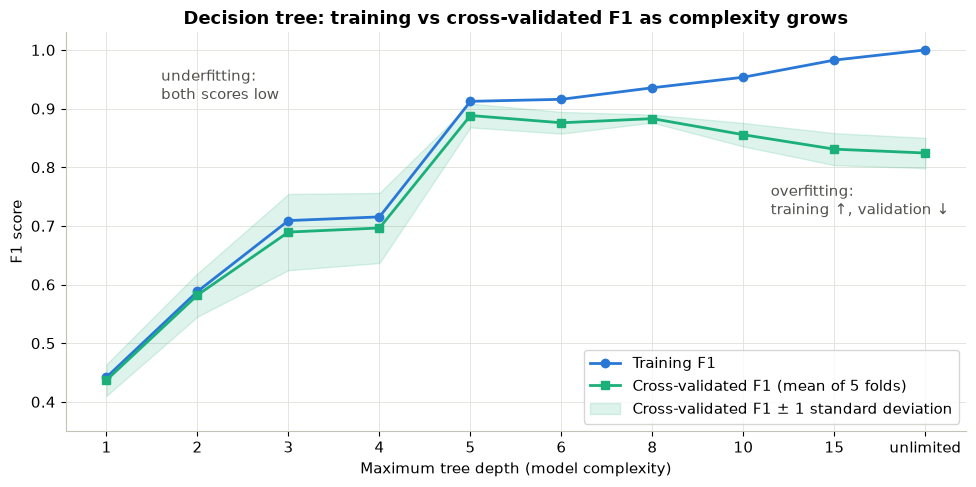

,max_depth,train_F1,cv_F1_mean,cv_F1_std,n_leaves
0,1,0.442,0.437,0.027,2
1,2,0.588,0.582,0.037,4
2,3,0.709,0.689,0.065,6
3,4,0.715,0.696,0.060,8
4,5,0.912,0.888,0.020,10
5,6,0.916,0.876,0.019,15
6,8,0.935,0.883,0.007,27
7,10,0.953,0.855,0.020,36
8,15,0.983,0.831,0.027,53
9,unlimited,1.000,0.824,0.026,66


In [40]:
depth_rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(tree, X_train, y_train, cv=cv, scoring="f1")
    tree.fit(X_train, y_train)
    depth_rows.append({
        "max_depth": "unlimited" if depth is None else str(depth),
        "train_F1": f1_score(y_train, tree.predict(X_train)),
        "cv_F1_mean": cv_scores.mean(),
        "cv_F1_std": cv_scores.std(),
        "n_leaves": tree.get_n_leaves(),
    })
depth_df = pd.DataFrame(depth_rows)

positions = np.arange(len(depth_df))
plt.figure(figsize=(10, 5))
plt.plot(positions, depth_df["train_F1"], marker="o", color=COLOR_OK, linewidth=2, label="Training F1")
plt.plot(positions, depth_df["cv_F1_mean"], marker="s", color=COLOR_ALT, linewidth=2, label="Cross-validated F1 (mean of 5 folds)")
plt.fill_between(positions, depth_df["cv_F1_mean"] - depth_df["cv_F1_std"], depth_df["cv_F1_mean"] + depth_df["cv_F1_std"],
                 color=COLOR_ALT, alpha=0.15, label="Cross-validated F1 ± 1 standard deviation")
plt.xticks(positions, depth_df["max_depth"])
plt.text(0.6, 0.97, "underfitting:\nboth scores low", color=COLOR_REF, va="top")
plt.text(7.3, 0.72, "overfitting:\ntraining ↑, validation ↓", color=COLOR_REF)
plt.ylim(0.35, 1.03)
plt.xlabel("Maximum tree depth (model complexity)")
plt.ylabel("F1 score")
plt.title("Decision tree: training vs cross-validated F1 as complexity grows")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

depth_df.round(3)

**Interpretation: the bias–variance trade-off, measured.**

* **Depth 1–4: underfitting.** Training and validation $F_1$ are both low and close together: the tree has too few questions to describe all the failure mechanisms.
* **Depth 5–8: the sweet spot.** Validation $F_1$ jumps to about 0.88–0.89, and the gap between training and validation stays small (0.02–0.05).
* **Depth 10 and beyond: overfitting.** Training $F_1$ keeps climbing to a perfect 1.0, while validation $F_1$ *falls* (to about 0.82 for an unlimited tree with 66 leaves). The extra branches memorise individual training processes, including random noise, instead of general rules.

We now let **`GridSearchCV`** choose the depth and two other settings by cross-validated $F_1$: `min_samples_leaf` (the minimum number of processes in a final leaf, which stops the tree from making rules for single points) and `criterion` (how the quality of a split is measured: Gini impurity or entropy).

In [41]:
param_grid_tree = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["gini", "entropy"],
}
grid_tree = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                         param_grid=param_grid_tree, cv=cv, scoring="f1")
grid_tree.fit(X_train, y_train)
best_tree = grid_tree.best_estimator_

print("Best parameters             :", grid_tree.best_params_)
print(f"Best cross-validated F1     : {grid_tree.best_score_:.3f}")

results["Decision Tree (tuned)"] = evaluate(best_tree, X_train, y_train, X_test, y_test)
results["Decision Tree (tuned)"]["cv_F1"] = grid_tree.best_score_

# For comparison: the unlimited (fully grown) tree from the sweep
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
results["Decision Tree (unlimited depth)"] = evaluate(full_tree, X_train, y_train, X_test, y_test)
results["Decision Tree (unlimited depth)"]["cv_F1"] = depth_df.loc[depth_df["max_depth"] == "unlimited", "cv_F1_mean"].iloc[0]
pd.Series(results["Decision Tree (tuned)"]).round(3)

Best parameters             : {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 1}
Best cross-validated F1     : 0.888


train_F1          0.920
test_accuracy     0.993
test_precision    0.934
test_recall       0.864
test_F1           0.898
test_ROC_AUC      0.974
cv_F1             0.888
dtype: float64

### 6.6 Model 3: Random Forest

A random forest trains many decision trees, each on a different bootstrap sample of the training data, and lets them **vote**. Averaging many trees reduces the variance (overfitting) of a single deep tree. We tune two settings:

* `max_depth`: unlimited trees, or trees limited to depth 8;
* `max_features`: how many features each split may consider (`"sqrt"` = a random subset of $\sqrt{10} \approx 3$, or `None` = all 10).

The forest uses 100 trees. `n_jobs=-1` only tells the computer to build the trees on all processor cores in parallel; it does not change the result.

In [42]:
param_grid_rf = {
    "max_depth": [None, 8],
    "max_features": ["sqrt", None],
}
grid_rf = GridSearchCV(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
                       param_grid=param_grid_rf, cv=cv, scoring="f1")
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_

print("Best parameters         :", grid_rf.best_params_)
print(f"Best cross-validated F1 : {grid_rf.best_score_:.3f}")
print()
print(pd.DataFrame(grid_rf.cv_results_)[["params", "mean_test_score", "std_test_score"]].round(3).to_string(index=False))

results["Random Forest (tuned)"] = evaluate(best_rf, X_train, y_train, X_test, y_test)
results["Random Forest (tuned)"]["cv_F1"] = grid_rf.best_score_

Best parameters         : {'max_depth': 8, 'max_features': None}
Best cross-validated F1 : 0.891

                                     params  mean_test_score  std_test_score
{'max_depth': None, 'max_features': 'sqrt'}            0.889           0.024
  {'max_depth': None, 'max_features': None}            0.884           0.021
   {'max_depth': 8, 'max_features': 'sqrt'}            0.889           0.025
     {'max_depth': 8, 'max_features': None}            0.891           0.025


All four forest settings score within about 0.01 of each other, which is *smaller* than the fold-to-fold standard deviation (about 0.02). In other words, **tuning the forest barely matters here**; the features matter far more (Section 6.8). We keep the best combination, but it would be wrong to claim it is clearly better than the others.

### 6.7 Model comparison

In [43]:
# Add the trivial baseline, then compare all models side by side
results_table = pd.DataFrame(results).T
baseline_row = pd.DataFrame([{
    "train_F1": 0.0, "cv_F1": 0.0,
    "test_accuracy": accuracy_score(y_test, always_no_failure),
    "test_precision": 0.0, "test_recall": 0.0, "test_F1": 0.0, "test_ROC_AUC": 0.5,
}], index=["Always 'no failure'"])
results_table = pd.concat([baseline_row, results_table])
results_table = results_table[["train_F1", "cv_F1", "test_accuracy", "test_precision", "test_recall", "test_F1", "test_ROC_AUC"]]
results_table.round(3)

,train_F1,cv_F1,test_accuracy,test_precision,test_recall,test_F1,test_ROC_AUC
Always 'no failure',0.000,0.000,0.967,0.000,0.000,0.000,0.500
Logistic Regression,0.380,0.363,0.971,0.800,0.182,0.296,0.945
Decision Tree (tuned),0.920,0.888,0.993,0.934,0.864,0.898,0.974
Decision Tree (unlimited depth),1.000,0.824,0.990,0.851,0.864,0.857,0.929
Random Forest (tuned),0.935,0.891,0.994,0.951,0.879,0.913,0.989


**Interpretation: which model, and how well does it generalise?**

| Model | Fit diagnosis | Evidence |
|---|---|---|
| Always "no failure" | useless | 96.7 % accuracy, 0 % recall |
| Logistic Regression | **underfits** | train ≈ CV $F_1$, both low; recall < 20 % |
| Decision Tree, unlimited | **overfits** | train $F_1$ = 1.00, CV $F_1$ ≈ 0.82 |
| Decision Tree, tuned | good fit | train ≈ 0.92, CV ≈ 0.89, test ≈ 0.90 |
| Random Forest, tuned | good fit, best scores | train ≈ 0.94, CV ≈ 0.89, test $F_1$ ≈ 0.91, ROC-AUC ≈ 0.99 |

For the tuned models, the cross-validated and test scores agree closely, so the estimates are trustworthy: the test score is not the result of one lucky split. The **Random Forest** gives the best test performance: it catches about **88 % of failures, and about 95 % of its alarms are real**. The **tuned Decision Tree** is almost as good and is fully transparent: an engineer can read every rule it uses (Section 6.10). On a shop floor that transparency can be worth more than the last point of $F_1$.

### 6.8 How much do the engineered features help?

To measure the value of Section 5, we compare cross-validated $F_1$ (training data only, as always) **with and without** the three engineered features, keeping each model's settings fixed.

In [44]:
# Same models, same settings, two feature sets; scored by 5-fold cross-validation on the training set
ablation_models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    # ** unpacks the best-parameter dictionary into keyword arguments, e.g. max_depth=6
    "Decision Tree (tuned settings)": DecisionTreeClassifier(random_state=RANDOM_STATE, **grid_tree.best_params_),
    "Random Forest (tuned settings)": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1,
                                                             **grid_rf.best_params_),
}
ablation_rows = []
for model_name, model in ablation_models.items():
    for set_name, cols in [("raw sensors only", FEATURES_RAW), ("raw + engineered", FEATURES_ALL)]:
        scores = cross_val_score(model, X_train[cols], y_train, cv=cv, scoring="f1")
        ablation_rows.append({"model": model_name, "features": set_name, "cv_F1": scores.mean()})

ablation = pd.DataFrame(ablation_rows).pivot_table(index="model", columns="features", values="cv_F1")
ablation = ablation[["raw sensors only", "raw + engineered"]]
ablation["improvement"] = ablation["raw + engineered"] - ablation["raw sensors only"]
ablation.round(3)

features,raw sensors only,raw + engineered,improvement
model,,,
Decision Tree (tuned settings),0.605,0.888,0.283
Logistic Regression,0.298,0.363,0.064
Random Forest (tuned settings),0.753,0.891,0.139


**Interpretation.**

* The **single decision tree** gains the most: cross-validated $F_1$ rises from about 0.61 to 0.89 (+0.28). With raw sensors it needs many splits to approximate a *curved* boundary such as constant power ($\tau = P/\omega$); with the power feature, one split is enough.
* The **random forest** gains less (+0.14): averaging many trees lets it approximate some of these combinations on its own, but the engineered features still help clearly.
* **Logistic regression** gains least (+0.06). A feature only helps if the model can use it, and a linear boundary still cannot represent a two-sided power window.

All of these gains are far larger than anything hyperparameter tuning achieved (6.6). **Good features, chosen from engineering knowledge, mattered more than model choice or tuning.**

### 6.9 Test-set evaluation: confusion matrices

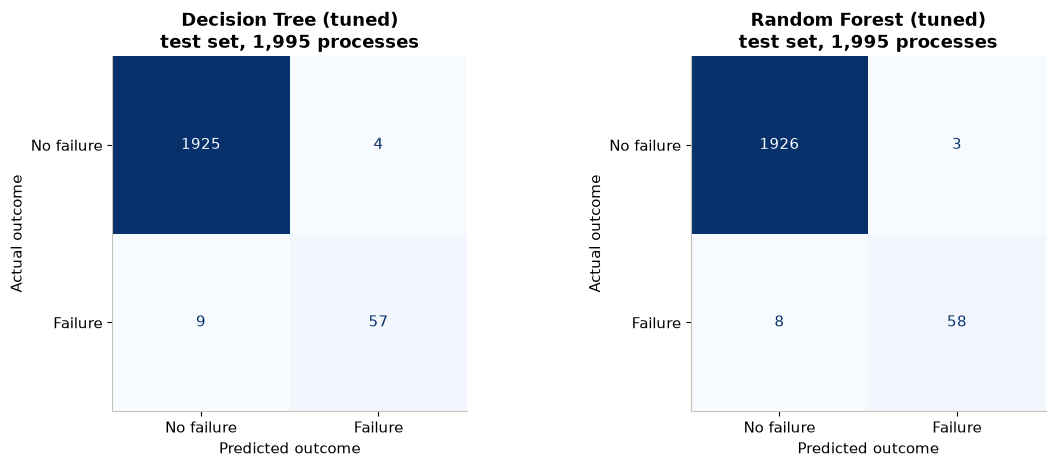

Random Forest (tuned), test set:
              precision    recall  f1-score   support

  No failure      0.996     0.998     0.997      1929
     Failure      0.951     0.879     0.913        66

    accuracy                          0.994      1995
   macro avg      0.973     0.939     0.955      1995
weighted avg      0.994     0.994     0.994      1995



In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, model) in zip(axes, [("Decision Tree (tuned)", best_tree), ("Random Forest (tuned)", best_rf)]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=STATUS_ORDER).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\ntest set, {len(y_test):,} processes")
    ax.set_xlabel("Predicted outcome")
    ax.set_ylabel("Actual outcome")
    ax.grid(False)
plt.tight_layout()
plt.show()

# Detailed per-class report for the best model
rf_test_pred = best_rf.predict(X_test)
print("Random Forest (tuned), test set:")
print(classification_report(y_test, rf_test_pred, target_names=STATUS_ORDER, digits=3))

**Interpretation (Random Forest, 1,995 test processes, 66 real failures).** The forest catches **58 of the 66 failures** (recall 0.88) and raises only **3 false alarms** among 1,929 normal processes (precision 0.95). **8 failures are missed.** For a maintenance team this means almost 9 of every 10 failures are flagged, at the cost of about one unnecessary stop per 640 normal processes. The tuned decision tree catches one failure fewer (57) and raises one false alarm more (4): nearly the same result from a model that can be read as a handful of rules.

### 6.10 What did the models learn?

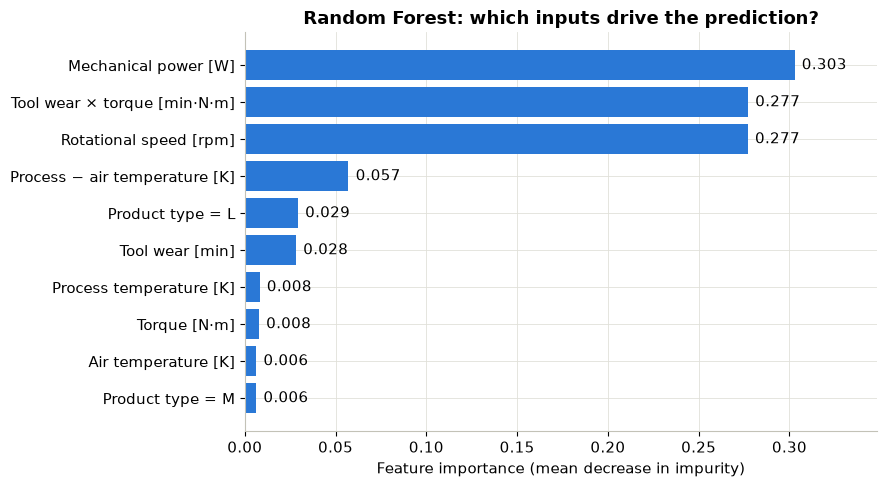

In [46]:
# Random Forest: impurity-based feature importance (how much each feature reduces impurity across all trees)
importance = pd.Series(best_rf.feature_importances_, index=FEATURES_ALL).sort_values()
readable = dict(LABELS)                      # copy the axis labels and add the two type columns
readable["type_L"] = "Product type = L"
readable["type_M"] = "Product type = M"

plt.figure(figsize=(9, 5))
plt.barh([readable[f] for f in importance.index], importance.values, color=COLOR_OK)
for i, value in enumerate(importance.values):
    plt.text(value + 0.004, i, f"{value:.3f}", va="center")
plt.xlabel("Feature importance (mean decrease in impurity)")
plt.title("Random Forest: which inputs drive the prediction?")
plt.xlim(0, importance.max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretation.** The most important inputs are **mechanical power**, **tool wear × torque** and **rotational speed**, followed by the **temperature difference**: two of the top three are engineered features, and each maps onto one physical failure mechanism. Raw torque on its own ranks low because its information is already contained in power and strain. (Caveat: impurity-based importance can favour continuous variables and splits the credit between related features, so the ranking is a guide, not a precise measurement.)

The tuned decision tree can be read directly. Below are its top five levels. Each box shows the split rule, the number of training processes that reach the box (`samples`), how many of them are normal and how many failed (`value = [normal, failed]`), and the majority class. Grey `(...)` boxes are deeper branches that are not drawn.

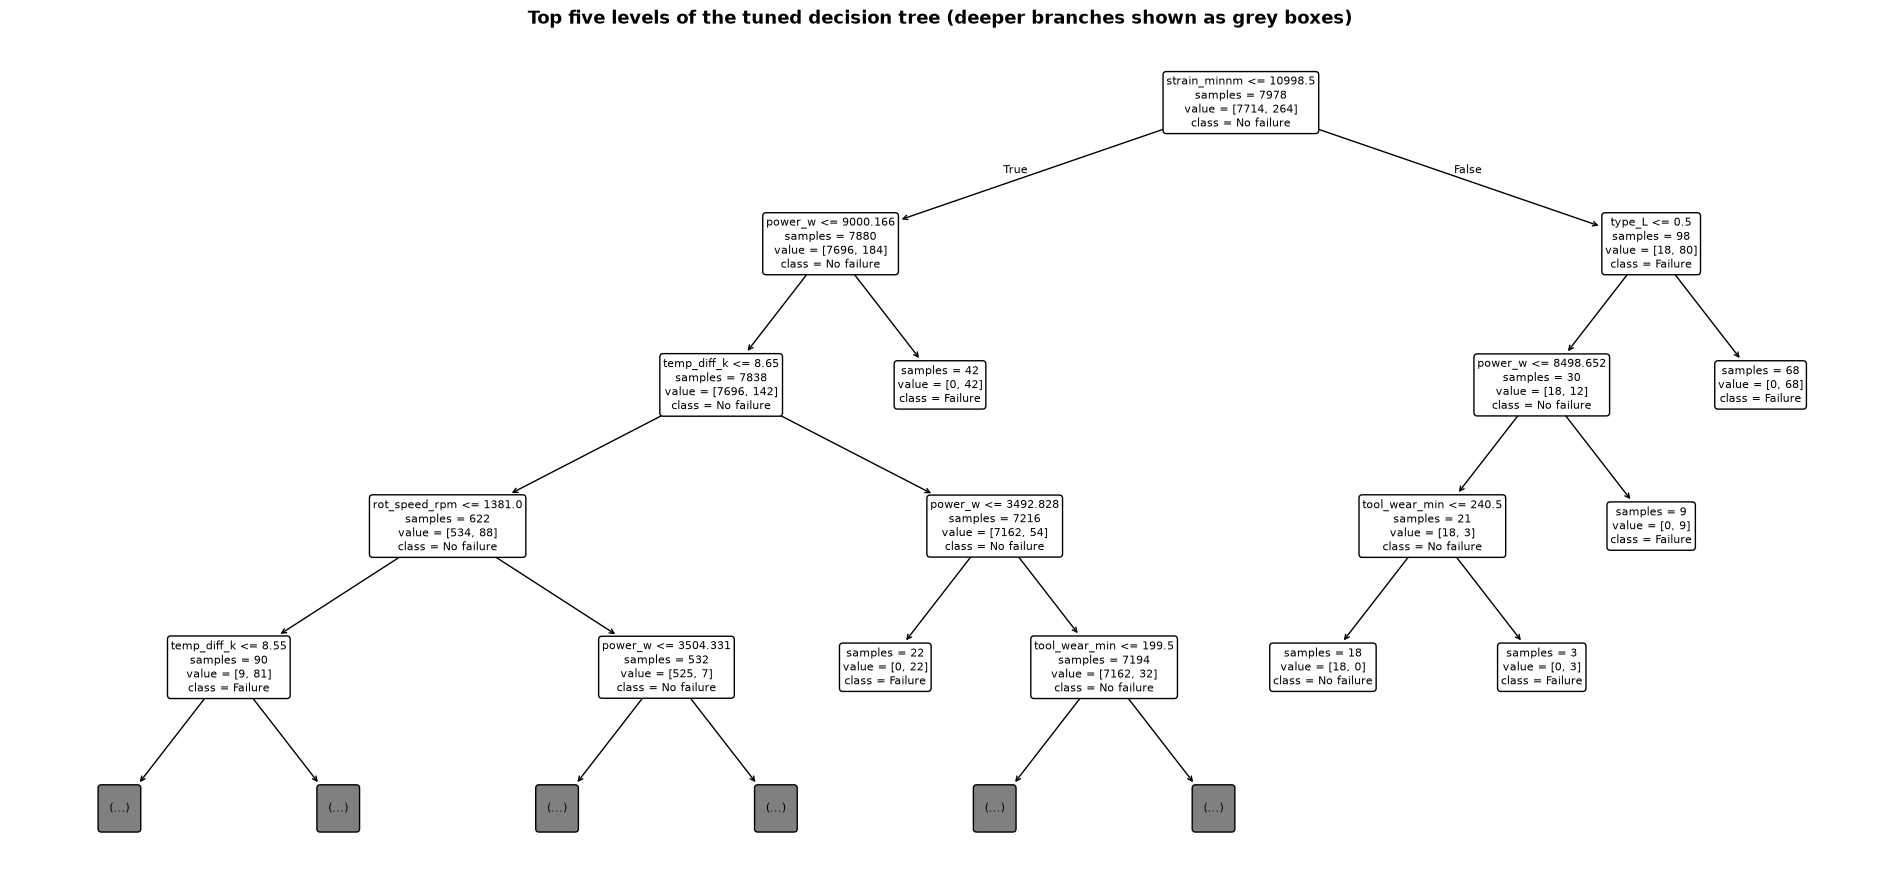

In [47]:
plt.figure(figsize=(24, 11))
plot_tree(best_tree, feature_names=FEATURES_ALL, class_names=STATUS_ORDER,
          filled=False, rounded=True, max_depth=4, fontsize=8, impurity=False)
plt.title("Top five levels of the tuned decision tree (deeper branches shown as grey boxes)")
plt.show()

**The tree rediscovered the documented failure physics from the data alone.** It was never shown the documented limits, yet its split values land almost exactly on them:

| Failure mechanism | Documented limit | Split learned by the tree |
|---|---|---|
| Overstrain, L products | wear × torque > 11,000 min·N·m | root split `strain_minnm <= 10998.5`; above it, every L product (68 of 68) failed |
| Power, upper limit | power > 9,000 W | `power_w <= 9000.166`; above it, all 42 processes failed |
| Power, lower limit | power < 3,500 W | `power_w <= 3492.828` and `power_w <= 3504.331` |
| Heat dissipation | ΔT < 8.6 K **and** speed < 1,380 rpm | `temp_diff_k <= 8.65`, then `rot_speed_rpm <= 1381.0` |
| Tool wear | failure between 200 and 240 min of wear | `tool_wear_min <= 199.5` and `tool_wear_min <= 240.5` |

(The overstrain limits for M and H products, 12,000 and 13,000 min·N·m, concern very few training processes; the tree handles them in deeper branches using power and tool wear.)

This is strong evidence that the model learned **physical failure mechanisms** rather than quirks of the training sample. It also shows how such a model could be explained to the machine operators: as a short set of readable rules.

### 6.11 Error analysis: which failures are missed?

In [48]:
# Look up the failure mechanisms of the test processes (same row index as X_test)
test_rows = df_clean.loc[X_test.index]
caught = (y_test == 1) & (rf_test_pred == 1)
missed = (y_test == 1) & (rf_test_pred == 0)

error_table = pd.DataFrame({
    "failures_in_test_set": test_rows.loc[y_test == 1, MODE_COLS].sum(),
    "caught": test_rows.loc[caught, MODE_COLS].sum(),
    "missed": test_rows.loc[missed, MODE_COLS].sum(),
})
error_table["detection_rate_%"] = (error_table["caught"] / error_table["failures_in_test_set"] * 100).round(0)
error_table.index = [MODE_NAMES[m] for m in MODE_COLS]
error_table

,failures_in_test_set,caught,missed,detection_rate_%
Tool wear (TWF),7,1,6,14.0
Heat dissipation (HDF),25,23,2,92.0
Power (PWF),16,16,0,100.0
Overstrain (OSF),21,21,0,100.0
Random (RNF),0,0,0,NaN


**Interpretation: the most useful finding for the maintenance engineer.** (The mechanism totals can exceed the 66 failed processes because a process can fail through several mechanisms at once.)

* **Power and overstrain failures are all caught, and 23 of 25 heat-dissipation failures are.** These mechanisms are fixed functions of the *current* operating point, which the model sees.
* **Most tool-wear failures are missed** (only 1 of 7 caught); tool wear accounts for 6 of the 8 missed failures. This is not a model defect that more tuning could fix: according to the documentation, the tool fails or is replaced at a **randomly chosen moment between 200 and 240 minutes** of wear. Two processes with identical readings at 220 minutes can have different outcomes, so no snapshot model can tell which tool will fail next.
* **Engineering consequence:** tool-wear failure is better handled by a **maintenance policy** than by prediction. Replacing tools preventively at about 200 minutes, the start of the failure window, would eliminate these failures at the cost of some unused tool life. Model and policy complement each other.

### 6.12 Choosing the alarm threshold

By default a model raises an alarm when the predicted failure probability is at least 0.5. Lowering that threshold catches more failures but raises more false alarms. To study this **without touching the test set**, we use **out-of-fold predictions**: in each of the 5 cross-validation folds, a forest trained on the other four folds predicts the held-out fold, so every training process receives a probability from a model that never saw it.

In [49]:
# Out-of-fold failure probabilities for every training process
oof_prob = pd.Series(0.0, index=X_train.index)
for train_idx, val_idx in cv.split(X_train, y_train):
    fold_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, **grid_rf.best_params_)
    fold_model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    oof_prob.iloc[val_idx] = fold_model.predict_proba(X_train.iloc[val_idx])[:, 1]

# Precision, recall and error counts at different alarm thresholds
threshold_rows = []
for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    alarm = (oof_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, alarm).ravel()
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_train, alarm),
        "recall": recall_score(y_train, alarm),
        "F1": f1_score(y_train, alarm),
        "false_alarms": fp,
        "missed_failures": fn,
    })
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.round(3)

,threshold,precision,recall,F1,false_alarms,missed_failures
0,0.1,0.700,0.883,0.781,100,31
1,0.2,0.838,0.860,0.849,44,37
2,0.3,0.896,0.845,0.869,26,41
3,0.4,0.944,0.830,0.883,13,45
4,0.5,0.969,0.826,0.892,7,46
5,0.6,0.982,0.822,0.895,4,47
6,0.7,0.991,0.811,0.892,2,50


**Interpretation.** At the default threshold of 0.5 the forest is very precise (97 % of its alarms are real) and catches 83 % of the training failures out-of-fold. Lowering the threshold to 0.1 raises recall to 88 %, but false alarms jump from 7 to 100. Catching 15 more failures costs 93 more false alarms, so the lower threshold only pays off if **one missed failure costs more than about six unnecessary stops** ($93 / 15 \approx 6.2$). Many plants would accept that trade, because an unplanned breakdown with a scrapped part and a damaged spindle usually costs far more than a short inspection. The gain is limited, though: the failures that remain hard to catch are mostly tool-wear failures (6.11), and no threshold predicts those well.

We keep the default threshold of 0.5 for the results reported above; the final choice belongs to the plant, which knows its own costs. Because the test set was not used here, the test results in 6.7–6.9 remain an honest estimate. (The out-of-fold recall at 0.5, 0.83, is a little lower than the test recall, 0.88. With only 66 test failures, a difference of a few failures is normal sampling variation.)

### 6.13 Robustness check: train on the past, test on the future

The random split mixes processes from all periods. A deployed model, however, is always trained on the **past** and used on the **future**, and Section 3.5 showed that the failure risk drifts over time. We therefore also train on the **first 80 % of the production sequence** and test on the **last 20 %**.

In [50]:
# Chronological split: df_clean (and therefore X, y) is still in production order
cut = int(len(X) * 0.8)
X_past, X_future = X.iloc[:cut], X.iloc[cut:]
y_past, y_future = y.iloc[:cut], y.iloc[cut:]

chrono_rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, **grid_rf.best_params_)
chrono_rf.fit(X_past, y_past)
future_pred = chrono_rf.predict(X_future)

future_rows = df_clean.iloc[cut:]
print(f"Training period : processes 1–{cut:,}, {y_past.sum()} failures ({y_past.mean():.2%})")
print(f"Test period     : the last {len(X_future):,} processes, {y_future.sum()} failures ({y_future.mean():.2%})")
print()
print(f"Precision : {precision_score(y_future, future_pred):.3f}")
print(f"Recall    : {recall_score(y_future, future_pred):.3f}")
print(f"F1        : {f1_score(y_future, future_pred):.3f}")

# Which mechanisms are caught and missed in the later period?
future_missed = (y_future == 1) & (future_pred == 0)
future_caught = (y_future == 1) & (future_pred == 1)
chrono_table = pd.DataFrame({
    "failures_in_test_period": future_rows.loc[y_future == 1, MODE_COLS].sum(),
    "caught": future_rows.loc[future_caught, MODE_COLS].sum(),
    "missed": future_rows.loc[future_missed, MODE_COLS].sum(),
})
chrono_table.index = [MODE_NAMES[m] for m in MODE_COLS]
chrono_table

Training period : processes 1–7,978, 293 failures (3.67%)
Test period     : the last 1,995 processes, 37 failures (1.85%)

Precision : 1.000
Recall    : 0.730
F1        : 0.844


,failures_in_test_period,caught,missed
Tool wear (TWF),10,1,9
Heat dissipation (HDF),0,0,0
Power (PWF),10,9,1
Overstrain (OSF),21,20,1
Random (RNF),0,0,0


**Interpretation.** Trained on the past and tested on the future, the forest raises **no false alarms at all** (precision 1.00) and catches 27 of the 37 later failures (recall 0.73, $F_1$ 0.84). That recall is lower than the 0.88 of the random split, and the breakdown shows why. The later period happens to contain no heat-dissipation failures, but proportionally many more **tool-wear** failures (10 of 37, against 7 of 66 in the random test set), and **9 of the 10 missed failures involve tool wear**. Power and overstrain failures are still caught almost without exception.

**Engineering lesson:** a single headline score depends on the *mix* of failure mechanisms in the period it is measured on. Before deployment, a model should be validated on a later time period than it was trained on; once running, its performance should be monitored per failure mechanism, not only as one overall number.

## 7. Engineering Interpretation & Limitations

### 7.1 Answers to the analytical questions

**Q1, operating conditions: yes.** Failed processes run at a significantly higher torque (+10.8 N·m, +27 %; Welch $t = 11.8$, $p \approx 3 \times 10^{-27}$, large effect $d = 1.1$), with more tool wear (+38 min on average) and slightly warmer air. But "more is worse" is too simple: failures also occur at *very low* torque, and at both low and high speed. That is why speed shows no significant difference in its *mean*, even though it matters a great deal.

**Q2, product variant: yes, but modestly.** Failure depends on the variant ($\chi^2 = 15.2$, $p = 0.0005$): L products fail 3.9 % of the time, about 1.9 times as often as H products (2.0 %). The variants are machined under identical conditions (ANOVA $p = 0.87$ for torque, and no significant difference for any other operating variable), so the difference lies in the product's own tolerance, consistent with its lower documented overstrain limit.

**Q3, prediction: yes, for most failure mechanisms.** A tuned Random Forest detects 88 % of failures in unseen test data while 95 % of its alarms are real ($F_1 = 0.91$, ROC-AUC = 0.99), and a transparent decision tree comes close ($F_1 = 0.90$). Physics-based features (power, wear × torque, temperature difference) were the decisive ingredient (+0.14 to +0.28 in cross-validated $F_1$). Power, overstrain and heat-dissipation failures are predictable; tool-wear failures are not, because their timing within the 200–240 min window is random.

### 7.2 Practical implications for operating and maintaining the machine

1. **Compute power and wear × torque in real time.** Both come from signals the machine controller already measures (speed, torque, tool time). Alarming when a process approaches the edge of the power window, or when wear × torque approaches the variant's limit, addresses the two most predictable failure mechanisms.
2. **Replace tools on a wear schedule.** Tool-wear failures are random within a 200–240 min window and cannot be predicted from a snapshot. Preventive replacement at about 200 min removes them; the cost is unused tool life, which the plant can weigh against the cost of a failure.
3. **Watch cooling, not just temperature.** Heat-dissipation failures need *both* a small process–air temperature gap and a low spindle speed, and they cluster in time. Monitoring the *gap* (not the absolute temperature), improving ventilation in warm periods, and avoiding low-speed operation when the gap is small would prevent them.
4. **Use stricter limits for low-quality (L) jobs.** L products fail about twice as often as H products under identical operating conditions, because they tolerate less overstrain.
5. **Choose the alarm threshold from cost data.** Section 6.12 shows the trade-off; the right threshold depends on what a missed failure costs compared with an unnecessary stop.
6. **Prefer transparent rules where trust matters.** The tuned decision tree is almost as accurate as the forest and can be printed as a handful of rules that operators can check.

### 7.3 Model limitations

* **Optimistic performance.** The simulator generates most failures from sharp, deterministic thresholds, so they are almost perfectly separable. Real failures are gradual and noisy; expect lower recall and precision on a real machine.
* **Snapshot, not forecast.** The model judges the current process from its own readings. It does not estimate *remaining useful life* or give hours of warning, which real maintenance planning often needs.
* **Few failures to learn from and test on.** The test set holds 66 failures, so a single extra missed failure changes recall by 1.5 percentage points. Fold-to-fold variation in cross-validation (standard deviation about 0.02 in $F_1$) is a better guide to the uncertainty than the third decimal place of any score.
* **Random failures are unpredictable** by definition, and tool-wear failures are random in their exact timing (Section 6.11).
* **Feature importance** from a random forest is a rough guide; it can favour continuous variables and share credit unevenly between related features.

### 7.4 Data quality constraints

* The data are **synthetic**: generated by a documented simulation, not measured on a real machine.
* **27 records had contradictory labels**, and the documentation's TWF and RNF counts do not match the file. Even a well-known benchmark dataset needs its labels checked.
* Only **five process variables** are available. Real condition monitoring would add vibration, motor current or acoustic emission, which often warn of failure much earlier.
* There are **no timestamps**: we know the order of the processes but not the time between them, so we cannot analyse daily or seasonal effects directly.
* The noise is idealised: there is no sensor drift, no calibration error and no missing data, all of which are common on real machines.

### 7.5 From simulation to a real machine: what this simulation does not model

This project is purely software, but its natural next step is deployment on a real machine tool. These are the assumptions that would break first:

| In this simulation | On a real machine |
|---|---|
| Sensors are perfectly calibrated; noise is small and well-behaved | Sensors drift, need recalibration, saturate and occasionally drop out (missing data) |
| One machine, one tool type, fixed physics | Several machines that differ from each other; tool suppliers and materials change over time (*concept drift*), so a model must be monitored and retrained |
| Every failure is labelled instantly and correctly | Labels come from maintenance logs written by people: late, incomplete, sometimes wrong |
| Failure thresholds are sharp (e.g. exactly 9,000 W) | Failure is gradual and probabilistic; thresholds blur |
| Readings are available the moment a process starts | Data arrive with latency; a prediction is only useful if it arrives before the failure develops |
| Units are consistent (K, rpm, N·m) | Mixed units and conventions (°C vs K, rpm vs rad/s) are a classic integration error, as the power formula shows |
| 3.3 % failure rate | Real failure rates are often far lower, making the imbalance problem harder still |

### 7.6 Ethical and operational considerations

* **Safety first.** A missed failure can mean a broken tool or a damaged spindle, and a breaking tool can injure people. The model must **support** existing safety interlocks (hard torque and power limits in the controller), never replace them.
* **Alarm fatigue.** Too many false alarms train operators to ignore alarms, which destroys the value of the system. The alarm threshold must be set with the people who respond to it.
* **Human in the loop.** The model should *recommend* an inspection or tool change; a qualified technician decides. Responsibility for maintenance decisions must stay clearly assigned.
* **Transparency.** Operators are more likely to trust (and correctly challenge) a system whose rules they can read, which favours the interpretable decision tree.
* **Use of the data.** The data describe machine health and should not be repurposed to judge individual operators' performance without their knowledge and consent.

### 7.7 Conclusion

Starting from 10,000 simulated machining processes, we removed 27 records with contradictory labels, kept the extreme operating points as signal rather than noise, and found through EDA and hypothesis testing that failures are tied to mechanical load, tool wear and cooling conditions, and to a smaller degree to the product variant. Three features derived from basic physics turned weak, non-linear raw signals into clear failure boundaries. With them, a decision tree rediscovered the machine's documented failure limits on its own, and a random forest caught almost nine in ten failures with very few false alarms. The remaining blind spot, tool-wear failures with random timing, is best closed by a preventive tool-change policy rather than by a better model. Because the data are synthetic and the failure rules sharp, these results are an upper bound: on a real machine, the same approach would need sensor-quality checks, time-based validation and ongoing monitoring before anyone relies on it.

## 8. References

1. Matzka, S. (2020). *Explainable Artificial Intelligence for Predictive Maintenance Applications.* International Conference on Artificial Intelligence for Industries (AI4I 2020). https://doi.org/10.1109/AI4I49448.2020.00023
2. *AI4I 2020 Predictive Maintenance Dataset* [Dataset] (2020). UCI Machine Learning Repository. https://doi.org/10.24432/C5HS5C (licence: CC BY 4.0)
3. EGN 2203 course materials: lectures 2.2 *Hypothesis Testing*, 4.2 *Machine Learning – Supervised*, 5.2 *Decision Tree* and 5.3 *Random Forest*; Lab 2 monographs on hypothesis testing and ANOVA; the decision-tree, random-forest and supervised-learning companion notebooks.
4. scikit-learn developers. *Metrics and scoring: quantifying the quality of predictions.* https://scikit-learn.org/stable/modules/model_evaluation.html
5. SciPy developers. *scipy.stats.ttest_ind* (Welch's t-test with `equal_var=False`). https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html
6. statsmodels developers. *ANOVA.* https://www.statsmodels.org/stable/anova.html